# PH/PH/1 Stationary Performance Experiment — Combined, Dataset-Size, and SCV-Regime Analysis


## 1. Setup

In [1]:
from pathlib import Path
import json
import math
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t as student_t
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

SERVICE_MEAN = 1.0
BASE_SEED = 321

N_REPLICATIONS = 30
SIM_WARMUP_TIME = 10_000.0
SIM_RECORD_TIME = 40_000.0

CHECK_RHOS = [0.30, 0.70, 0.95]
CHECK_ARRIVAL_SCVS = [0.25, 1.00, 2.00]
CHECK_SERVICE_SCVS = [0.25, 1.00, 2.00]

N_CONFIGURATIONS = 300
N_VALIDATION = 30
N_TEST = 30
N_TRAIN = 240

OUTPUT_DIR = Path("PHPH1_stationary_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Canonical PH construction

In [2]:
def build_ph_distribution(mean, scv, tol=1e-12):
    """Construct a moment-matched canonical PH distribution."""
    if mean <= 0:
        raise ValueError("mean must be positive")
    if scv <= 0:
        raise ValueError("scv must be positive")

    m = float(mean)
    c2 = float(scv)

    if abs(c2 - 1.0) <= tol:
        rate = 1.0 / m
        alpha = np.array([1.0], dtype=float)
        T = np.array([[-rate]], dtype=float)
        family = "exponential"

    elif c2 < 1.0:
        k = max(2, int(math.ceil((1.0 / c2) - 1e-12)))
        n = k - 1

        disc = max(n * ((n + 1) * c2 - 1.0), 0.0)
        x = (n - math.sqrt(disc)) / (n * (n + 1))

        a = m * x
        b = m * (1.0 - n * x)

        if a <= 0 or b <= 0:
            raise RuntimeError(f"Invalid sequential PH construction for SCV={c2}")

        phase_means = np.array([a] * n + [b], dtype=float)
        rates = 1.0 / phase_means

        alpha = np.zeros(k, dtype=float)
        alpha[0] = 1.0

        T = np.zeros((k, k), dtype=float)
        for i, rate in enumerate(rates):
            T[i, i] = -rate
            if i < k - 1:
                T[i, i + 1] = rate

        family = "generalized_erlang"

    else:
        p = 0.5 * (1.0 + math.sqrt((c2 - 1.0) / (c2 + 1.0)))
        rate_1 = 2.0 * p / m
        rate_2 = 2.0 * (1.0 - p) / m

        alpha = np.array([p, 1.0 - p], dtype=float)
        T = np.diag([-rate_1, -rate_2]).astype(float)
        family = "hyperexponential_2"

    return {
        "alpha": alpha,
        "T": T,
        "family": family,
        "phase_count": int(len(alpha)),
    }


def ph_moments(alpha, T):
    alpha = np.asarray(alpha, dtype=float)
    T = np.asarray(T, dtype=float)

    ones = np.ones(T.shape[0])
    first_vector = np.linalg.solve(-T, ones)
    second_vector = 2.0 * np.linalg.solve(-T, first_vector)

    mean = float(alpha @ first_vector)
    second_moment = float(alpha @ second_vector)
    variance = second_moment - mean**2
    scv = variance / mean**2

    return {
        "mean": mean,
        "second_moment": second_moment,
        "variance": variance,
        "scv": scv,
    }


for requested_scv in [0.25, 0.65, 1.0, 1.55, 2.0]:
    ph = build_ph_distribution(1.0, requested_scv)
    m = ph_moments(ph["alpha"], ph["T"])
    assert np.isclose(m["mean"], 1.0, atol=1e-10)
    assert np.isclose(m["scv"], requested_scv, atol=1e-10)

print("PH moment-matching checks passed.")

PH moment-matching checks passed.


## 3. PH/PH/1 QBD benchmark

For levels \(n\ge 1\), the background state contains the current arrival phase and current service phase.  
Let \(t_A=-T_A\mathbf 1\) and \(t_S=-T_S\mathbf 1\). The interior QBD blocks are

\[
A_{\uparrow}=(t_A\alpha_A)\otimes I_S,
\]

\[
A_0=T_A\otimes I_S + I_A\otimes T_S,
\]

\[
A_{\downarrow}=I_A\otimes(t_S\alpha_S).
\]

The rate matrix \(R\) solves

\[
A_{\uparrow}+RA_0+R^2A_{\downarrow}=0.
\]

The boundary level \(0\) contains only the arrival phase. After solving the matrix-geometric stationary distribution, \(L_q\) is obtained and

\[
W_q = \frac{L_q}{\lambda}
\]

is calculated using Little's Law.

In [3]:
def build_phph1_qbd_blocks(arrival_ph, service_ph):
    alpha_a = np.asarray(arrival_ph["alpha"], dtype=float)
    T_a = np.asarray(arrival_ph["T"], dtype=float)
    alpha_s = np.asarray(service_ph["alpha"], dtype=float)
    T_s = np.asarray(service_ph["T"], dtype=float)

    m_a = len(alpha_a)
    m_s = len(alpha_s)

    I_a = np.eye(m_a)
    I_s = np.eye(m_s)

    t_a = -T_a @ np.ones(m_a)
    t_s = -T_s @ np.ones(m_s)

    A_up = np.kron(np.outer(t_a, alpha_a), I_s)
    A_same = np.kron(T_a, I_s) + np.kron(I_a, T_s)
    A_down = np.kron(I_a, np.outer(t_s, alpha_s))

    B00 = T_a.copy()
    B01 = np.kron(
        np.outer(t_a, alpha_a),
        alpha_s.reshape(1, -1),
    )
    B10 = np.kron(
        I_a,
        t_s.reshape(-1, 1),
    )

    return B00, B01, B10, A_up, A_same, A_down


def solve_rate_matrix_R(A_up, A_same, A_down, tol=1e-12, max_iter=20_000):
    """Functional iteration for the minimal nonnegative QBD rate matrix R."""
    d = A_same.shape[0]
    R = np.zeros((d, d), dtype=float)

    for iteration in range(1, max_iter + 1):
        M = A_same + R @ A_down
        R_new = np.linalg.solve(M.T, -A_up.T).T

        err = float(np.max(np.abs(R_new - R)))
        R = R_new

        if err < tol:
            return R, iteration, err

    raise RuntimeError("QBD rate-matrix iteration did not converge")


def phph1_qbd_benchmark(
    rho,
    arrival_scv,
    service_scv,
    service_mean=SERVICE_MEAN,
    tol=1e-12,
):
    """Matrix-geometric stationary benchmark for the canonical PH/PH/1 queue."""
    if not (0 < rho < 1):
        raise ValueError("rho must lie in (0,1)")

    service_ph = build_ph_distribution(service_mean, service_scv)
    service_mom = ph_moments(service_ph["alpha"], service_ph["T"])

    lambda_rate = rho / service_mom["mean"]
    arrival_mean = 1.0 / lambda_rate

    arrival_ph = build_ph_distribution(arrival_mean, arrival_scv)
    arrival_mom = ph_moments(arrival_ph["alpha"], arrival_ph["T"])

    B00, B01, B10, A_up, A_same, A_down = build_phph1_qbd_blocks(
        arrival_ph,
        service_ph,
    )

    start = time.perf_counter()
    R, iterations, last_change = solve_rate_matrix_R(
        A_up, A_same, A_down, tol=tol
    )

    d = R.shape[0]
    m_a = len(arrival_ph["alpha"])

    spectral_radius = float(np.max(np.abs(np.linalg.eigvals(R))))
    if spectral_radius >= 1.0 + 1e-9:
        raise RuntimeError("Unstable/invalid QBD rate matrix")

    boundary = np.block([
        [B00, B01],
        [B10, A_same + R @ A_down],
    ])

    inv_I_minus_R = np.linalg.inv(np.eye(d) - R)

    mass_vector = np.concatenate([
        np.ones(m_a),
        inv_I_minus_R @ np.ones(d),
    ])

    M = boundary.T.copy()
    rhs = np.zeros(M.shape[0], dtype=float)

    M[-1, :] = mass_vector
    rhs[-1] = 1.0

    p = np.linalg.solve(M, rhs)

    pi0 = p[:m_a]
    pi1 = p[m_a:]

    p0 = float(pi0.sum())

    L = float(
        pi1
        @ inv_I_minus_R
        @ inv_I_minus_R
        @ np.ones(d)
    )

    busy_probability = 1.0 - p0
    Lq = float(L - busy_probability)

    W = L / lambda_rate
    Wq = Lq / lambda_rate

    qbd_residual = float(
        np.linalg.norm(
            A_up + R @ A_same + R @ R @ A_down,
            ord=np.inf,
        )
    )
    boundary_residual = float(
        np.linalg.norm(p @ boundary, ord=np.inf)
    )
    qbd_seconds = time.perf_counter() - start

    return {
        "rho": float(rho),
        "lambda_rate": float(lambda_rate),
        "arrival_mean": float(arrival_mom["mean"]),
        "arrival_scv": float(arrival_mom["scv"]),
        "service_mean": float(service_mom["mean"]),
        "service_scv": float(service_mom["scv"]),
        "arrival_ph_family": arrival_ph["family"],
        "arrival_phase_count": arrival_ph["phase_count"],
        "service_ph_family": service_ph["family"],
        "service_phase_count": service_ph["phase_count"],
        "P0_qbd": p0,
        "busy_probability_qbd": busy_probability,
        "L_qbd": L,
        "Lq_qbd": Lq,
        "W_qbd": W,
        "Wq_qbd": Wq,
        "R_spectral_radius": spectral_radius,
        "R_iterations": int(iterations),
        "R_last_change": float(last_change),
        "qbd_residual": qbd_residual,
        "boundary_residual": boundary_residual,
        "qbd_seconds": qbd_seconds,
        "arrival_ph": arrival_ph,
        "service_ph": service_ph,
    }

### 3.1 QBD sanity checks against M/M/1 and M/PH/1

In [4]:
mm1_rows = []
for rho in [0.30, 0.70, 0.95]:
    q = phph1_qbd_benchmark(rho, 1.0, 1.0)
    mm1_wq = rho / (1.0 - rho)

    mm1_rows.append({
        "rho": rho,
        "QBD_Wq": q["Wq_qbd"],
        "M_M_1_Wq": mm1_wq,
        "abs_diff": abs(q["Wq_qbd"] - mm1_wq),
        "P0_qbd": q["P0_qbd"],
        "1-rho": 1-rho,
    })

mm1_check = pd.DataFrame(mm1_rows)
display(mm1_check)

assert np.allclose(
    mm1_check["QBD_Wq"],
    mm1_check["M_M_1_Wq"],
    atol=1e-8,
)

mph1_rows = []
for rho in [0.30, 0.70, 0.95]:
    for service_scv in [0.25, 1.0, 2.0]:
        q = phph1_qbd_benchmark(rho, 1.0, service_scv)
        pk_wq = rho * (1.0 + service_scv) / (2.0 * (1.0 - rho))

        mph1_rows.append({
            "rho": rho,
            "service_scv": service_scv,
            "QBD_Wq": q["Wq_qbd"],
            "M_PH_1_PK_Wq": pk_wq,
            "abs_diff": abs(q["Wq_qbd"] - pk_wq),
        })

mph1_check = pd.DataFrame(mph1_rows)
display(mph1_check)

assert np.allclose(
    mph1_check["QBD_Wq"],
    mph1_check["M_PH_1_PK_Wq"],
    atol=1e-8,
)

print("QBD sanity checks passed.")

,rho,QBD_Wq,M_M_1_Wq,abs_diff,P0_qbd,1-rho
0,0.30,0.428571,0.428571,4.881651e-13,0.70,0.70
1,0.70,2.333333,2.333333,2.836220e-11,0.30,0.30
2,0.95,19.000000,19.000000,7.912536e-09,0.05,0.05


,rho,service_scv,QBD_Wq,M_PH_1_PK_Wq,abs_diff
0,0.30,0.25,0.267857,0.267857,5.168088e-13
1,0.30,1.00,0.428571,0.428571,4.881651e-13
2,0.30,2.00,0.642857,0.642857,1.681211e-12
3,0.70,0.25,1.458333,1.458333,1.232836e-11
4,0.70,1.00,2.333333,2.333333,2.836220e-11
5,0.70,2.00,3.500000,3.500000,7.482770e-11
6,0.95,0.25,11.875000,11.875000,4.031332e-09
7,0.95,1.00,19.000000,19.000000,7.912536e-09
8,0.95,2.00,28.500000,28.500000,2.017422e-08


QBD sanity checks passed.


## 4. Fixed-time PH/PH/1 simulator

In [5]:
def sample_ph_durations(rng, ph, size):
    """Fast sampler for the canonical PH families used in this notebook."""
    family = ph["family"]
    alpha = np.asarray(ph["alpha"], dtype=float)
    T = np.asarray(ph["T"], dtype=float)
    rates = -np.diag(T)

    if family == "exponential":
        return rng.exponential(scale=1.0 / rates[0], size=size)

    if family == "generalized_erlang":
        k = len(rates)

        if np.allclose(rates, rates[0]):
            return rng.gamma(
                shape=k,
                scale=1.0 / rates[0],
                size=size,
            )

        n_equal = k - 1
        x = rng.gamma(
            shape=n_equal,
            scale=1.0 / rates[0],
            size=size,
        )
        x += rng.exponential(
            scale=1.0 / rates[-1],
            size=size,
        )
        return x

    if family == "hyperexponential_2":
        branch = rng.choice(len(alpha), size=size, p=alpha)
        return rng.exponential(scale=1.0 / rates[branch])

    raise ValueError(f"Unsupported PH family: {family}")


def generate_ph_renewal_arrivals_until(rng, arrival_ph, end_time):
    """Generate renewal arrivals with iid PH interarrival times."""
    moments = ph_moments(arrival_ph["alpha"], arrival_ph["T"])
    mean_interarrival = moments["mean"]

    expected = end_time / mean_interarrival
    n_initial = max(
        100,
        int(expected + 12.0 * math.sqrt(max(expected, 1.0)) + 100),
    )

    interarrival = sample_ph_durations(
        rng,
        arrival_ph,
        n_initial,
    )
    arrivals = np.cumsum(interarrival)

    while arrivals[-1] < end_time:
        batch_size = max(100, int(0.05 * n_initial))
        extra = sample_ph_durations(
            rng,
            arrival_ph,
            batch_size,
        )
        interarrival = np.concatenate([interarrival, extra])
        arrivals = np.concatenate([
            arrivals,
            arrivals[-1] + np.cumsum(extra),
        ])

    keep = arrivals < end_time
    return interarrival[keep], arrivals[keep]


def simulate_phph1_fixed_time(
    rho,
    arrival_scv,
    service_scv,
    arrival_ph,
    service_ph,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
    seed=123,
):
    """One fixed-time PH/PH/1 replication."""
    if not (0 < rho < 1):
        raise ValueError("rho must lie in (0,1)")

    seed_sequence = np.random.SeedSequence(int(seed))
    arrival_seed, service_seed = seed_sequence.spawn(2)
    rng_arrival = np.random.default_rng(arrival_seed)
    rng_service = np.random.default_rng(service_seed)

    horizon_end = warmup_time + record_time

    interarrival_time, arrival_time = generate_ph_renewal_arrivals_until(
        rng_arrival,
        arrival_ph,
        horizon_end,
    )

    n_customers = len(arrival_time)
    if n_customers == 0:
        raise RuntimeError("No customers generated")

    service_time = sample_ph_durations(
        rng_service,
        service_ph,
        n_customers,
    )

    cumulative_service = np.cumsum(service_time)

    cumulative_before = np.empty(n_customers)
    cumulative_before[0] = 0.0
    cumulative_before[1:] = cumulative_service[:-1]

    running_offset = np.maximum.accumulate(
        arrival_time - cumulative_before
    )
    departure_time = cumulative_service + running_offset
    service_start = departure_time - service_time

    waiting_time = service_start - arrival_time
    system_time = departure_time - arrival_time

    cohort = (
        (arrival_time >= warmup_time)
        & (arrival_time < horizon_end)
    )

    if cohort.sum() == 0:
        raise RuntimeError("No arrivals in the recording cohort")

    cohort_interarrival = interarrival_time[cohort]
    cohort_service = service_time[cohort]
    cohort_wait = waiting_time[cohort]
    cohort_system = system_time[cohort]

    arrival_mean_hat = float(cohort_interarrival.mean())
    arrival_scv_hat = float(
        cohort_interarrival.var(ddof=0) / arrival_mean_hat**2
    )

    service_mean_hat = float(cohort_service.mean())
    service_scv_hat = float(
        cohort_service.var(ddof=0) / service_mean_hat**2
    )

    lambda_hat = float(cohort.sum() / record_time)

    return {
        "Wq_sim": float(cohort_wait.mean()),
        "W_sim": float(cohort_system.mean()),
        "lambda_hat": lambda_hat,
        "arrival_mean_hat": arrival_mean_hat,
        "arrival_scv_hat": arrival_scv_hat,
        "service_mean_hat": service_mean_hat,
        "service_scv_hat": service_scv_hat,
        "n_record_arrivals": int(cohort.sum()),
        "n_generated_arrivals": int(n_customers),
    }

## 5. Replications and configuration-level labels

In [6]:
def run_replications_for_config(
    config_id,
    rho,
    arrival_scv,
    service_scv,
    stream_id,
    seed_namespace,
    replications=N_REPLICATIONS,
    warmup_time=SIM_WARMUP_TIME,
    record_time=SIM_RECORD_TIME,
    service_mean=SERVICE_MEAN,
    base_seed=BASE_SEED,
):
    benchmark = phph1_qbd_benchmark(
        rho=rho,
        arrival_scv=arrival_scv,
        service_scv=service_scv,
        service_mean=service_mean,
    )

    arrival_ph = benchmark["arrival_ph"]
    service_ph = benchmark["service_ph"]

    rows = []

    for rep in range(replications):
        seed = (
            int(base_seed)
            + int(seed_namespace) * 10_000_000
            + int(stream_id) * 1_000
            + rep
        )

        if seed >= 2**32 - 1:
            raise ValueError("seed exceeds NumPy 32-bit seed range")

        start = time.perf_counter()
        sim = simulate_phph1_fixed_time(
            rho=rho,
            arrival_scv=arrival_scv,
            service_scv=service_scv,
            arrival_ph=arrival_ph,
            service_ph=service_ph,
            warmup_time=warmup_time,
            record_time=record_time,
            seed=seed,
        )
        elapsed = time.perf_counter() - start

        rows.append({
            "config_id": config_id,
            "stream_id": int(stream_id),
            "seed_namespace": int(seed_namespace),
            "rho": float(rho),
            "lambda_rate": benchmark["lambda_rate"],
            "arrival_mean": benchmark["arrival_mean"],
            "arrival_scv": benchmark["arrival_scv"],
            "service_mean": benchmark["service_mean"],
            "service_scv": benchmark["service_scv"],
            "arrival_ph_family": benchmark["arrival_ph_family"],
            "arrival_phase_count": benchmark["arrival_phase_count"],
            "service_ph_family": benchmark["service_ph_family"],
            "service_phase_count": benchmark["service_phase_count"],
            "warmup_time": float(warmup_time),
            "record_time": float(record_time),
            "replication": rep + 1,
            "seed": int(seed),
            "runtime_seconds": float(elapsed),
            "Wq_qbd": benchmark["Wq_qbd"],
            "Lq_qbd": benchmark["Lq_qbd"],
            "P0_qbd": benchmark["P0_qbd"],
            "R_spectral_radius": benchmark["R_spectral_radius"],
            "qbd_residual": benchmark["qbd_residual"],
            **sim,
        })

    return pd.DataFrame(rows)


def aggregate_configuration_labels(replication_df):
    rows = []

    group_cols = [
        "config_id",
        "rho",
        "lambda_rate",
        "arrival_mean",
        "arrival_scv",
        "service_mean",
        "service_scv",
        "arrival_ph_family",
        "arrival_phase_count",
        "service_ph_family",
        "service_phase_count",
        "warmup_time",
        "record_time",
    ]

    for keys, g in replication_df.groupby(group_cols, sort=True):
        (
            config_id,
            rho,
            lambda_rate,
            arrival_mean,
            arrival_scv,
            service_mean,
            service_scv,
            arrival_ph_family,
            arrival_phase_count,
            service_ph_family,
            service_phase_count,
            warmup_time,
            record_time,
        ) = keys

        wq = g["Wq_sim"].to_numpy(dtype=float)
        Rn = len(wq)

        mean = float(wq.mean())
        sd = float(wq.std(ddof=1))
        se = sd / math.sqrt(Rn)
        tcrit = float(student_t.ppf(0.975, df=Rn - 1))
        hw = tcrit * se

        wq_qbd = float(g["Wq_qbd"].iloc[0])
        lq_qbd = float(g["Lq_qbd"].iloc[0])

        rows.append({
            "config_id": config_id,
            "rho": float(rho),
            "lambda_rate": float(lambda_rate),
            "arrival_mean": float(arrival_mean),
            "arrival_scv": float(arrival_scv),
            "service_mean": float(service_mean),
            "service_scv": float(service_scv),
            "arrival_ph_family": arrival_ph_family,
            "arrival_phase_count": int(arrival_phase_count),
            "service_ph_family": service_ph_family,
            "service_phase_count": int(service_phase_count),
            "warmup_time": float(warmup_time),
            "record_time": float(record_time),
            "n_replications": int(Rn),

            "Wq_qbd": wq_qbd,
            "Wq_sim_mean": mean,
            "Wq_rep_sd": sd,
            "Wq_se": se,
            "Wq_ci95_low": mean - hw,
            "Wq_ci95_high": mean + hw,
            "Wq_ci95_halfwidth": hw,
            "Wq_relative_ci_halfwidth_pct": 100.0 * hw / abs(mean),
            "Wq_abs_error_vs_qbd": abs(mean - wq_qbd),
            "Wq_rel_error_vs_qbd_pct": 100.0 * abs(mean - wq_qbd) / abs(wq_qbd),
            "CI_contains_qbd": bool((mean - hw <= wq_qbd) and (wq_qbd <= mean + hw)),

            "Lq_qbd": lq_qbd,
            "Lq_derived_from_Wq": float(lambda_rate * mean),

            "lambda_hat_mean": float(g["lambda_hat"].mean()),
            "arrival_mean_hat_mean": float(g["arrival_mean_hat"].mean()),
            "arrival_scv_hat_mean": float(g["arrival_scv_hat"].mean()),
            "service_mean_hat_mean": float(g["service_mean_hat"].mean()),
            "service_scv_hat_mean": float(g["service_scv_hat"].mean()),

            "P0_qbd": float(g["P0_qbd"].iloc[0]),
            "R_spectral_radius": float(g["R_spectral_radius"].iloc[0]),
            "qbd_residual": float(g["qbd_residual"].iloc[0]),
            "mean_runtime_seconds_per_rep": float(g["runtime_seconds"].mean()),
        })

    return pd.DataFrame(rows)

## 6. Protocol-transfer check

The inherited M/PH/1 horizon is **not automatically assumed to be final** for PH/PH/1.

A \(3\times 3\times 3=27\) check covers

\[
\rho\in\{0.30,0.70,0.95\},\quad
SCV_A\in\{0.25,1,2\},\quad
SCV_S\in\{0.25,1,2\}.
\]

The simulation mean and 95% confidence interval are compared with the QBD benchmark. Heavy-traffic cases should receive particular attention.

In [7]:
check_design = (
    pd.MultiIndex.from_product(
        [CHECK_RHOS, CHECK_ARRIVAL_SCVS, CHECK_SERVICE_SCVS],
        names=["rho", "arrival_scv", "service_scv"],
    )
    .to_frame(index=False)
)

check_design.insert(
    0,
    "config_id",
    [f"check_{i:02d}" for i in range(len(check_design))],
)
check_design["stream_id"] = np.arange(len(check_design), dtype=int)

check_frames = []
for row in check_design.itertuples(index=False):
    print(
        f"{row.config_id}: rho={row.rho:.2f}, "
        f"SCV_A={row.arrival_scv:.2f}, SCV_S={row.service_scv:.2f}"
    )
    check_frames.append(
        run_replications_for_config(
            config_id=row.config_id,
            rho=row.rho,
            arrival_scv=row.arrival_scv,
            service_scv=row.service_scv,
            stream_id=row.stream_id,
            seed_namespace=10,
        )
    )

check_replications = pd.concat(check_frames, ignore_index=True)
assert check_replications["seed"].is_unique

check_labels = aggregate_configuration_labels(check_replications)

check_summary = pd.DataFrame([{
    "n_configurations": len(check_labels),
    "mean_relative_error_pct": check_labels["Wq_rel_error_vs_qbd_pct"].mean(),
    "median_relative_error_pct": check_labels["Wq_rel_error_vs_qbd_pct"].median(),
    "max_relative_error_pct": check_labels["Wq_rel_error_vs_qbd_pct"].max(),
    "ci95_coverage_pct": 100.0 * check_labels["CI_contains_qbd"].mean(),
    "mean_relative_ci_halfwidth_pct": check_labels["Wq_relative_ci_halfwidth_pct"].mean(),
    "max_relative_ci_halfwidth_pct": check_labels["Wq_relative_ci_halfwidth_pct"].max(),
}])

display(check_summary.round(4))
display(
    check_labels.sort_values("Wq_rel_error_vs_qbd_pct", ascending=False)[
        [
            "rho", "arrival_scv", "service_scv",
            "Wq_qbd", "Wq_sim_mean",
            "Wq_rel_error_vs_qbd_pct",
            "Wq_relative_ci_halfwidth_pct",
            "CI_contains_qbd",
        ]
    ].head(10).round(4)
)

check_replications.to_csv(
    OUTPUT_DIR / "phph1_protocol_check_replications.csv",
    index=False,
)
check_labels.to_csv(
    OUTPUT_DIR / "phph1_protocol_check_labels.csv",
    index=False,
)

check_00: rho=0.30, SCV_A=0.25, SCV_S=0.25
check_01: rho=0.30, SCV_A=0.25, SCV_S=1.00
check_02: rho=0.30, SCV_A=0.25, SCV_S=2.00
check_03: rho=0.30, SCV_A=1.00, SCV_S=0.25
check_04: rho=0.30, SCV_A=1.00, SCV_S=1.00
check_05: rho=0.30, SCV_A=1.00, SCV_S=2.00
check_06: rho=0.30, SCV_A=2.00, SCV_S=0.25
check_07: rho=0.30, SCV_A=2.00, SCV_S=1.00
check_08: rho=0.30, SCV_A=2.00, SCV_S=2.00
check_09: rho=0.70, SCV_A=0.25, SCV_S=0.25
check_10: rho=0.70, SCV_A=0.25, SCV_S=1.00
check_11: rho=0.70, SCV_A=0.25, SCV_S=2.00
check_12: rho=0.70, SCV_A=1.00, SCV_S=0.25
check_13: rho=0.70, SCV_A=1.00, SCV_S=1.00
check_14: rho=0.70, SCV_A=1.00, SCV_S=2.00
check_15: rho=0.70, SCV_A=2.00, SCV_S=0.25
check_16: rho=0.70, SCV_A=2.00, SCV_S=1.00
check_17: rho=0.70, SCV_A=2.00, SCV_S=2.00
check_18: rho=0.95, SCV_A=0.25, SCV_S=0.25
check_19: rho=0.95, SCV_A=0.25, SCV_S=1.00
check_20: rho=0.95, SCV_A=0.25, SCV_S=2.00
check_21: rho=0.95, SCV_A=1.00, SCV_S=0.25
check_22: rho=0.95, SCV_A=1.00, SCV_S=1.00
check_23: r

,n_configurations,mean_relative_error_pct,median_relative_error_pct,max_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct,max_relative_ci_halfwidth_pct
0,27,1.7922,1.1173,10.8937,96.2963,3.8953,13.3479


,rho,arrival_scv,service_scv,Wq_qbd,Wq_sim_mean,Wq_rel_error_vs_qbd_pct,Wq_relative_ci_halfwidth_pct,CI_contains_qbd
25,0.95,2.00,1.00,28.4918,31.5956,10.8937,12.1310,True
26,0.95,2.00,2.00,38.0544,39.8351,4.6793,10.3772,True
18,0.95,0.25,0.25,4.5701,4.7681,4.3329,4.4287,True
23,0.95,1.00,2.00,28.5000,29.6392,3.9973,13.3479,True
22,0.95,1.00,1.00,19.0000,18.3462,3.4412,6.9349,True
0,0.30,0.25,0.25,0.0276,0.0266,3.4114,2.2706,False
2,0.30,0.25,2.00,0.3077,0.3016,1.9758,2.5366,True
1,0.30,0.25,1.00,0.1215,0.1193,1.8211,2.0234,True
17,0.70,2.00,2.00,4.6935,4.7637,1.4958,2.7871,True
24,0.95,2.00,0.25,21.2406,20.9650,1.2977,6.9005,True


check_13: rho=0.70, SCV_A=1.00, SCV_S=1.00


check_14: rho=0.70, SCV_A=1.00, SCV_S=2.00
check_15: rho=0.70, SCV_A=2.00, SCV_S=0.25


check_16: rho=0.70, SCV_A=2.00, SCV_S=1.00


... (3 outputs left out)

check_24: rho=0.95, SCV_A=2.00, SCV_S=0.25
check_25: rho=0.95, SCV_A=2.00, SCV_S=1.00


check_26: rho=0.95, SCV_A=2.00, SCV_S=2.00


,n_configurations,mean_relative_error_pct,median_relative_error_pct,max_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct,max_relative_ci_halfwidth_pct
0,27,1.7922,1.1173,10.8937,96.2963,3.8953,13.3479


,rho,arrival_scv,service_scv,Wq_qbd,Wq_sim_mean,Wq_rel_error_vs_qbd_pct,Wq_relative_ci_halfwidth_pct,CI_contains_qbd
25,0.95,2.00,1.00,28.4918,31.5956,10.8937,12.1310,True
26,0.95,2.00,2.00,38.0544,39.8351,4.6793,10.3772,True
18,0.95,0.25,0.25,4.5701,4.7681,4.3329,4.4287,True
23,0.95,1.00,2.00,28.5000,29.6392,3.9973,13.3479,True
22,0.95,1.00,1.00,19.0000,18.3462,3.4412,6.9349,True
0,0.30,0.25,0.25,0.0276,0.0266,3.4114,2.2706,False
2,0.30,0.25,2.00,0.3077,0.3016,1.9758,2.5366,True
1,0.30,0.25,1.00,0.1215,0.1193,1.8211,2.0234,True
17,0.70,2.00,2.00,4.6935,4.7637,1.4958,2.7871,True
24,0.95,2.00,0.25,21.2406,20.9650,1.2977,6.9005,True


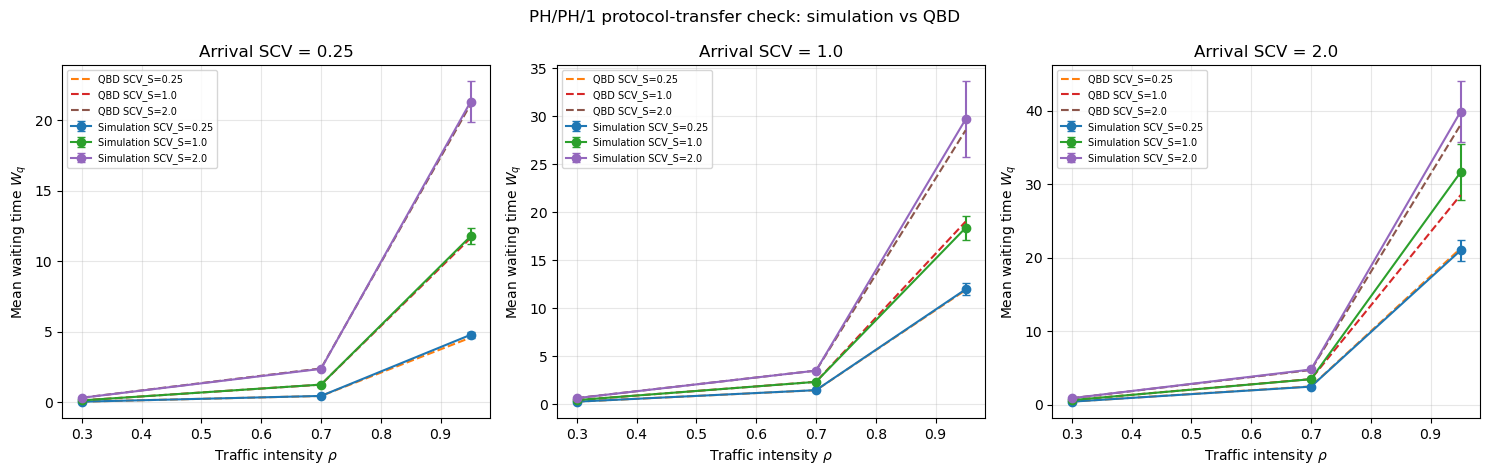

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=False)

for ax, arrival_scv in zip(axes, CHECK_ARRIVAL_SCVS):
    subset = check_labels[np.isclose(check_labels["arrival_scv"], arrival_scv)]

    for service_scv in CHECK_SERVICE_SCVS:
        tmp = subset[np.isclose(subset["service_scv"], service_scv)].sort_values("rho")

        yerr = np.vstack([
            tmp["Wq_sim_mean"] - tmp["Wq_ci95_low"],
            tmp["Wq_ci95_high"] - tmp["Wq_sim_mean"],
        ])

        ax.errorbar(
            tmp["rho"],
            tmp["Wq_sim_mean"],
            yerr=yerr,
            marker="o",
            capsize=3,
            label=f"Simulation SCV_S={service_scv}",
        )
        ax.plot(
            tmp["rho"],
            tmp["Wq_qbd"],
            linestyle="--",
            label=f"QBD SCV_S={service_scv}",
        )

    ax.set_title(f"Arrival SCV = {arrival_scv}")
    ax.set_xlabel(r"Traffic intensity $\rho$")
    ax.set_ylabel(r"Mean waiting time $W_q$")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle("PH/PH/1 protocol-transfer check: simulation vs QBD")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "phph1_protocol_transfer_check.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Optional longer-recording sensitivity check

If the transfer check shows materially wide confidence intervals or unstable heavy-traffic estimates, set `RUN_LONGER_RECORDING_CHECK = True` below. The optional block compares 40,000 and 80,000 recording time units for three demanding $\rho=0.95$ cases.

In [9]:
RUN_LONGER_RECORDING_CHECK = True

if RUN_LONGER_RECORDING_CHECK:
    sensitivity_cases = pd.DataFrame([
        {"rho": 0.95, "arrival_scv": 0.25, "service_scv": 2.0},
        {"rho": 0.95, "arrival_scv": 1.00, "service_scv": 2.0},
        {"rho": 0.95, "arrival_scv": 2.00, "service_scv": 2.0},
    ])

    sensitivity_frames = []
    for i, row in sensitivity_cases.iterrows():
        for record_time in [40_000.0, 80_000.0]:
            sensitivity_frames.append(
                run_replications_for_config(
                    config_id=f"sens_{i}_T{int(record_time)}",
                    rho=float(row["rho"]),
                    arrival_scv=float(row["arrival_scv"]),
                    service_scv=float(row["service_scv"]),
                    stream_id=100 + i * 2 + int(record_time == 80_000.0),
                    seed_namespace=11,
                    record_time=record_time,
                )
            )

    sensitivity_replications = pd.concat(sensitivity_frames, ignore_index=True)
    sensitivity_labels = aggregate_configuration_labels(sensitivity_replications)

    display(
        sensitivity_labels[
            [
                "rho", "arrival_scv", "service_scv", "record_time",
                "Wq_qbd", "Wq_sim_mean",
                "Wq_rel_error_vs_qbd_pct",
                "Wq_relative_ci_halfwidth_pct",
            ]
        ].round(4)
    )

,rho,arrival_scv,service_scv,record_time,Wq_qbd,Wq_sim_mean,Wq_rel_error_vs_qbd_pct,Wq_relative_ci_halfwidth_pct
0,0.95,0.25,2.0,40000.0,21.1155,21.8631,3.5406,8.3976
1,0.95,0.25,2.0,80000.0,21.1155,21.9010,3.7198,7.1355
2,0.95,1.00,2.0,40000.0,28.5000,27.4663,3.6269,9.5349
3,0.95,1.00,2.0,80000.0,28.5000,29.3330,2.9227,7.1091
4,0.95,2.00,2.0,40000.0,38.0544,39.0895,2.7199,12.0572
5,0.95,2.00,2.0,80000.0,38.0544,38.3314,0.7278,7.6678


## 7. Formal 300-configuration PH/PH/1 design

PH/PH/1 adds a third varying descriptor, arrival variability. Therefore the M/PH/1 two-dimensional 300-point design cannot simply be copied unchanged.

This controlled first PH/PH/1 design uses:

- 12 utilisation values, all taken from the earlier M/PH/1 base grid;
- 5 arrival-SCV values;
- 5 service-SCV values;

giving

\[
12\times5\times5=300
\]

configurations.

The \(SCV_A=1\) slice is an M/PH/1 slice, providing a direct cross-stage consistency bridge.

In [10]:
RHO_GRID_12 = np.array([
    0.30, 0.34, 0.40, 0.47, 0.54, 0.60,
    0.70, 0.77, 0.84, 0.87, 0.90, 0.95,
])

SCV_GRID_5 = np.array([0.25, 0.65, 1.00, 1.55, 2.00])

configuration_design = (
    pd.MultiIndex.from_product(
        [RHO_GRID_12, SCV_GRID_5, SCV_GRID_5],
        names=["rho", "arrival_scv", "service_scv"],
    )
    .to_frame(index=False)
)

configuration_design.insert(
    0,
    "config_id",
    [f"phph1_{i:03d}" for i in range(len(configuration_design))],
)

assert len(configuration_design) == N_CONFIGURATIONS

configuration_design["split"] = "train"
split_rng = np.random.default_rng(1)

for arrival_scv in SCV_GRID_5:
    idx = configuration_design.index[
        np.isclose(configuration_design["arrival_scv"], arrival_scv)
    ].to_numpy()

    permuted = split_rng.permutation(idx)
    test_idx = permuted[:6]
    validation_idx = permuted[6:12]

    configuration_design.loc[test_idx, "split"] = "test"
    configuration_design.loc[validation_idx, "split"] = "validation"

assert (configuration_design["split"] == "train").sum() == N_TRAIN
assert (configuration_design["split"] == "validation").sum() == N_VALIDATION
assert (configuration_design["split"] == "test").sum() == N_TEST

configuration_design["stream_id"] = np.arange(
    len(configuration_design),
    dtype=int,
)
configuration_design["seed_namespace"] = 20

configuration_design["rho_band"] = pd.cut(
    configuration_design["rho"],
    bins=[0.299, 0.50, 0.75, 0.90, 0.951],
    labels=["low", "moderate", "high", "very_high"],
    include_lowest=True,
)

print(configuration_design["split"].value_counts())
display(pd.crosstab(configuration_design["arrival_scv"], configuration_design["split"]))
display(pd.crosstab(configuration_design["service_scv"], configuration_design["split"]))
display(pd.crosstab(configuration_design["rho_band"], configuration_design["split"]))

configuration_design.to_csv(
    OUTPUT_DIR / "phph1_configuration_design_300.csv",
    index=False,
)

split
train         240
validation     30
test           30
Name: count, dtype: int64


split,test,train,validation
arrival_scv,,,
0.25,6,48,6
0.65,6,48,6
1.00,6,48,6
1.55,6,48,6
2.00,6,48,6


split,test,train,validation
service_scv,,,
0.25,3,51,6
0.65,4,49,7
1.00,7,48,5
1.55,5,46,9
2.00,11,46,3


split,test,train,validation
rho_band,,,
low,5,84,11
moderate,13,55,7
high,9,82,9
very_high,3,19,3


## 8. Generate the 300 configuration-level stationary labels

In [11]:
def generate_full_replication_dataset(design_df):
    frames = []
    start_all = time.perf_counter()

    for j, row in enumerate(design_df.itertuples(index=False), start=1):
        if j == 1 or j % 25 == 0 or j == len(design_df):
            print(
                f"[{j}/{len(design_df)}] {row.config_id} "
                f"rho={row.rho:.2f}, "
                f"SCV_A={row.arrival_scv:.2f}, "
                f"SCV_S={row.service_scv:.2f}"
            )

        frames.append(
            run_replications_for_config(
                config_id=row.config_id,
                rho=float(row.rho),
                arrival_scv=float(row.arrival_scv),
                service_scv=float(row.service_scv),
                stream_id=int(row.stream_id),
                seed_namespace=int(row.seed_namespace),
            )
        )

    full_replications = pd.concat(frames, ignore_index=True)

    expected_rows = len(design_df) * N_REPLICATIONS
    assert len(full_replications) == expected_rows
    assert full_replications["seed"].is_unique

    elapsed = time.perf_counter() - start_all
    print(f"Full label generation completed in {elapsed/60:.2f} minutes.")

    return full_replications


full_replications = generate_full_replication_dataset(configuration_design)

stationary_labels = aggregate_configuration_labels(full_replications)

stationary_labels = stationary_labels.merge(
    configuration_design[
        [
            "config_id", "split", "rho_band",
            "stream_id", "seed_namespace",
        ]
    ],
    on="config_id",
    how="left",
    validate="one_to_one",
)

full_replications.to_csv(
    OUTPUT_DIR / "phph1_300_replications.csv",
    index=False,
)
stationary_labels.to_csv(
    OUTPUT_DIR / "phph1_300_stationary_labels.csv",
    index=False,
)

display(stationary_labels.head())

[1/300] phph1_000 rho=0.30, SCV_A=0.25, SCV_S=0.25
[25/300] phph1_024 rho=0.30, SCV_A=2.00, SCV_S=2.00
[50/300] phph1_049 rho=0.34, SCV_A=2.00, SCV_S=2.00
[75/300] phph1_074 rho=0.40, SCV_A=2.00, SCV_S=2.00
[100/300] phph1_099 rho=0.47, SCV_A=2.00, SCV_S=2.00
[125/300] phph1_124 rho=0.54, SCV_A=2.00, SCV_S=2.00
[150/300] phph1_149 rho=0.60, SCV_A=2.00, SCV_S=2.00
[175/300] phph1_174 rho=0.70, SCV_A=2.00, SCV_S=2.00
[200/300] phph1_199 rho=0.77, SCV_A=2.00, SCV_S=2.00
[225/300] phph1_224 rho=0.84, SCV_A=2.00, SCV_S=2.00
[250/300] phph1_249 rho=0.87, SCV_A=2.00, SCV_S=2.00
[275/300] phph1_274 rho=0.90, SCV_A=2.00, SCV_S=2.00
[300/300] phph1_299 rho=0.95, SCV_A=2.00, SCV_S=2.00
Full label generation completed in 0.24 minutes.


,config_id,rho,lambda_rate,arrival_mean,arrival_scv,service_mean,service_scv,arrival_ph_family,arrival_phase_count,service_ph_family,...,service_mean_hat_mean,service_scv_hat_mean,P0_qbd,R_spectral_radius,qbd_residual,mean_runtime_seconds_per_rep,split,rho_band,stream_id,seed_namespace
0,phph1_000,0.3,0.3,3.333333,0.25,1.0,0.25,generalized_erlang,4,generalized_erlang,...,0.998479,0.249150,0.7,0.008100,4.331638e-14,0.001234,train,low,0,20
1,phph1_001,0.3,0.3,3.333333,0.25,1.0,0.65,generalized_erlang,4,generalized_erlang,...,1.001681,0.651670,0.7,0.064845,1.098305e-13,0.000828,train,low,1,20
2,phph1_002,0.3,0.3,3.333333,0.25,1.0,1.00,generalized_erlang,4,exponential,...,1.001483,1.003754,0.7,0.108331,2.398515e-13,0.000484,train,low,2,20
3,phph1_003,0.3,0.3,3.333333,0.25,1.0,1.55,generalized_erlang,4,hyperexponential_2,...,0.999950,1.542824,0.7,0.257790,1.290183e-12,0.000954,validation,low,3,20
4,phph1_004,0.3,0.3,3.333333,0.25,1.0,2.00,generalized_erlang,4,hyperexponential_2,...,1.003157,2.008414,0.7,0.335517,9.398801e-13,0.000954,train,low,4,20


[100/300] phph1_099 rho=0.47, SCV_A=2.00, SCV_S=2.00


[125/300] phph1_124 rho=0.54, SCV_A=2.00, SCV_S=2.00


[150/300] phph1_149 rho=0.60, SCV_A=2.00, SCV_S=2.00


[175/300] phph1_174 rho=0.70, SCV_A=2.00, SCV_S=2.00


... (2 outputs left out)

[250/300] phph1_249 rho=0.87, SCV_A=2.00, SCV_S=2.00


[275/300] phph1_274 rho=0.90, SCV_A=2.00, SCV_S=2.00


[300/300] phph1_299 rho=0.95, SCV_A=2.00, SCV_S=2.00
Full label generation completed in 0.29 minutes.


,config_id,rho,lambda_rate,arrival_mean,arrival_scv,service_mean,service_scv,arrival_ph_family,arrival_phase_count,service_ph_family,service_phase_count,warmup_time,record_time,n_replications,Wq_qbd,Wq_sim_mean,Wq_rep_sd,Wq_se,Wq_ci95_low,Wq_ci95_high,Wq_ci95_halfwidth,Wq_relative_ci_halfwidth_pct,Wq_abs_error_vs_qbd,Wq_rel_error_vs_qbd_pct,CI_contains_qbd,Lq_qbd,Lq_derived_from_Wq,lambda_hat_mean,arrival_mean_hat_mean,arrival_scv_hat_mean,service_mean_hat_mean,service_scv_hat_mean,P0_qbd,R_spectral_radius,qbd_residual,mean_runtime_seconds_per_rep,split,rho_band,stream_id,seed_namespace
0,phph1_000,0.3,0.3,3.333333,0.25,1.0,0.25,generalized_erlang,4,generalized_erlang,4,10000.0,40000.0,30,0.027585,0.027092,0.001737,0.000317,0.026444,0.027741,0.000649,2.394483,0.000493,1.786330,True,0.008276,0.008128,0.299748,3.336213,0.250274,0.998479,0.249150,0.7,0.008100,4.350968e-14,0.001277,train,low,0,20
1,phph1_001,0.3,0.3,3.333333,0.25,1.0,0.65,generalized_erlang,4,generalized_erlang,2,10000.0,40000.0,30,0.074843,0.076100,0.003143,0.000574,0.074926,0.077274,0.001174,1.542369,0.001257,1.679488,False,0.022453,0.022830,0.299855,3.335002,0.249676,1.001681,0.651670,0.7,0.064845,1.098253e-13,0.001063,train,low,1,20
2,phph1_002,0.3,0.3,3.333333,0.25,1.0,1.00,generalized_erlang,4,exponential,1,10000.0,40000.0,30,0.121493,0.122522,0.007018,0.001281,0.119901,0.125142,0.002620,2.138793,0.001029,0.846986,True,0.036448,0.036756,0.300205,3.331090,0.249110,1.001483,1.003754,0.7,0.108331,2.398515e-13,0.000912,train,low,2,20
3,phph1_003,0.3,0.3,3.333333,0.25,1.0,1.55,generalized_erlang,4,hyperexponential_2,2,10000.0,40000.0,30,0.221267,0.220315,0.016359,0.002987,0.214206,0.226423,0.006108,2.772581,0.000952,0.430252,True,0.066380,0.066094,0.299971,3.333755,0.248789,0.999950,1.542824,0.7,0.257790,1.290183e-12,0.001182,validation,low,3,20
4,phph1_004,0.3,0.3,3.333333,0.25,1.0,2.00,generalized_erlang,4,hyperexponential_2,2,10000.0,40000.0,30,0.307653,0.314443,0.024126,0.004405,0.305434,0.323452,0.009009,2.864992,0.006789,2.206848,True,0.092296,0.094333,0.300128,3.331928,0.249126,1.003157,2.008414,0.7,0.335517,9.399374e-13,0.001128,train,low,4,20


### 8.1 Input-process and simulation-label diagnostics

In [12]:
stationary_labels["lambda_rel_error_pct"] = (
    100.0
    * (stationary_labels["lambda_hat_mean"] - stationary_labels["lambda_rate"]).abs()
    / stationary_labels["lambda_rate"].abs()
)

stationary_labels["arrival_scv_rel_error_pct"] = (
    100.0
    * (stationary_labels["arrival_scv_hat_mean"] - stationary_labels["arrival_scv"]).abs()
    / stationary_labels["arrival_scv"].abs()
)

stationary_labels["service_scv_rel_error_pct"] = (
    100.0
    * (stationary_labels["service_scv_hat_mean"] - stationary_labels["service_scv"]).abs()
    / stationary_labels["service_scv"].abs()
)

input_validation = pd.DataFrame([{
    "n_configurations": len(stationary_labels),
    "mean_lambda_rel_error_pct": stationary_labels["lambda_rel_error_pct"].mean(),
    "max_lambda_rel_error_pct": stationary_labels["lambda_rel_error_pct"].max(),
    "mean_arrival_scv_rel_error_pct": stationary_labels["arrival_scv_rel_error_pct"].mean(),
    "max_arrival_scv_rel_error_pct": stationary_labels["arrival_scv_rel_error_pct"].max(),
    "mean_service_scv_rel_error_pct": stationary_labels["service_scv_rel_error_pct"].mean(),
    "max_service_scv_rel_error_pct": stationary_labels["service_scv_rel_error_pct"].max(),
}])

simulation_quality = pd.DataFrame([{
    "n_configurations": len(stationary_labels),
    "mean_relative_error_pct": stationary_labels["Wq_rel_error_vs_qbd_pct"].mean(),
    "median_relative_error_pct": stationary_labels["Wq_rel_error_vs_qbd_pct"].median(),
    "p90_relative_error_pct": stationary_labels["Wq_rel_error_vs_qbd_pct"].quantile(0.90),
    "p95_relative_error_pct": stationary_labels["Wq_rel_error_vs_qbd_pct"].quantile(0.95),
    "ci95_coverage_pct": 100.0 * stationary_labels["CI_contains_qbd"].mean(),
    "mean_relative_ci_halfwidth_pct": stationary_labels["Wq_relative_ci_halfwidth_pct"].mean(),
}])

quality_by_rho = (
    stationary_labels
    .groupby("rho_band", observed=False)
    .agg(
        n_configurations=("config_id", "count"),
        mean_relative_error_pct=("Wq_rel_error_vs_qbd_pct", "mean"),
        p90_relative_error_pct=("Wq_rel_error_vs_qbd_pct", lambda x: x.quantile(0.90)),
        ci95_coverage_pct=("CI_contains_qbd", lambda x: 100.0*x.mean()),
        mean_relative_ci_halfwidth_pct=("Wq_relative_ci_halfwidth_pct", "mean"),
    )
    .reset_index()
)

print("Input-process validation:")
display(input_validation.round(4))

print("Overall simulation-label quality vs QBD:")
display(simulation_quality.round(4))

print("Simulation-label quality by traffic band:")
display(quality_by_rho.round(4))

input_validation.to_csv(
    OUTPUT_DIR / "phph1_input_validation_summary.csv",
    index=False,
)
simulation_quality.to_csv(
    OUTPUT_DIR / "phph1_simulation_quality_summary.csv",
    index=False,
)
quality_by_rho.to_csv(
    OUTPUT_DIR / "phph1_simulation_quality_by_rho.csv",
    index=False,
)

Input-process validation:


,n_configurations,mean_lambda_rel_error_pct,max_lambda_rel_error_pct,mean_arrival_scv_rel_error_pct,max_arrival_scv_rel_error_pct,mean_service_scv_rel_error_pct,max_service_scv_rel_error_pct
0,300,0.098,0.6939,0.2065,1.2178,0.2293,1.5038


Overall simulation-label quality vs QBD:


,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,p95_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,300,1.13,0.7985,2.3598,3.4593,91.6667,2.6783


Simulation-label quality by traffic band:


,rho_band,n_configurations,mean_relative_error_pct,p90_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,low,100,0.7791,1.6802,88.0000,1.6252
1,moderate,75,0.7668,1.6562,90.6667,1.6418
2,high,100,1.3328,2.5317,94.0000,3.1664
3,very_high,25,2.8118,4.7015,100.0000,8.0476


In [13]:
# Cross-stage consistency:
# when arrival SCV = 1, PH/PH/1 reduces to M/PH/1 for this setup.
mph1_slice = stationary_labels[
    np.isclose(stationary_labels["arrival_scv"], 1.0)
].copy()

mph1_slice["PK_Wq"] = (
    mph1_slice["rho"]
    * (1.0 + mph1_slice["service_scv"])
    / (2.0 * (1.0 - mph1_slice["rho"]))
)

mph1_slice["QBD_minus_PK_abs"] = (
    mph1_slice["Wq_qbd"] - mph1_slice["PK_Wq"]
).abs()

print("Maximum |QBD - M/PH/1 PK| on SCV_A = 1 slice:")
print(mph1_slice["QBD_minus_PK_abs"].max())

assert mph1_slice["QBD_minus_PK_abs"].max() < 1e-7

Maximum |QBD - M/PH/1 PK| on SCV_A = 1 slice:
2.0174223180902118e-08


## 9. ML experiment

Primary prediction problem:

\[
(\rho,\mathrm{SCV}_A,\mathrm{SCV}_S)\longrightarrow \widehat W_q.
\]

The model is trained on the **simulation mean label** `Wq_sim_mean`, preserving the simulation-to-ML pipeline used in the earlier stage.

The QBD value is retained as an independent matrix-analytic benchmark.

In [14]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    abs_error = np.abs(y_pred - y_true)
    rel_error_pct = 100.0 * abs_error / np.abs(y_true)

    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": rmse(y_true, y_pred),
        "R2": float(r2_score(y_true, y_pred)),
        "MAPE_pct": float(rel_error_pct.mean()),
        "Median_APE_pct": float(np.median(rel_error_pct)),
    }


feature_cols = ["rho", "arrival_scv", "service_scv"]
target_col = "Wq_sim_mean"

train_df = stationary_labels[stationary_labels["split"] == "train"].copy()
val_df = stationary_labels[stationary_labels["split"] == "validation"].copy()
test_df = stationary_labels[stationary_labels["split"] == "test"].copy()

assert len(train_df) == 240
assert len(val_df) == 30
assert len(test_df) == 30

X_train = train_df[feature_cols]
y_train = train_df[target_col]
X_val = val_df[feature_cols]
y_val = val_df[target_col]
X_test = test_df[feature_cols]

### 9.1 Validation-only hyperparameter selection

In [15]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_val_rmse = rmse(y_val, lr.predict(X_val))

dt_candidates = [
    {"max_depth": 3, "min_samples_leaf": 1},
    {"max_depth": 4, "min_samples_leaf": 1},
    {"max_depth": 5, "min_samples_leaf": 1},
    {"max_depth": 6, "min_samples_leaf": 1},
    {"max_depth": 4, "min_samples_leaf": 2},
    {"max_depth": 5, "min_samples_leaf": 2},
    {"max_depth": None, "min_samples_leaf": 2},
]

rf_candidates = [
    {"n_estimators": 300, "max_depth": 5, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_depth": 8, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    {"n_estimators": 300, "max_depth": 8, "min_samples_leaf": 2},
    {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 2},
]

xgb_candidates = [
    {"n_estimators": 250, "max_depth": 2, "learning_rate": 0.03},
    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 400, "max_depth": 3, "learning_rate": 0.03},
    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 400, "max_depth": 3, "learning_rate": 0.05},
    {"n_estimators": 300, "max_depth": 4, "learning_rate": 0.03},
]


def select_by_validation(model_name, candidate_params):
    rows = []

    for params in candidate_params:
        if model_name == "Decision Tree":
            model = DecisionTreeRegressor(
                random_state=BASE_SEED,
                **params,
            )

        elif model_name == "Random Forest":
            model = RandomForestRegressor(
                random_state=BASE_SEED,
                n_jobs=-1,
                **params,
            )

        elif model_name == "XGBoost":
            model = XGBRegressor(
                random_state=BASE_SEED,
                objective="reg:squarederror",
                n_jobs=-1,
                verbosity=0,
                **params,
            )

        else:
            raise ValueError(model_name)

        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start

        pred = model.predict(X_val)

        rows.append({
            **params,
            "validation_RMSE_vs_sim_label": rmse(y_val, pred),
            "training_seconds": fit_seconds,
        })

    result = pd.DataFrame(rows).sort_values(
        "validation_RMSE_vs_sim_label"
    ).reset_index(drop=True)

    return result


dt_search = select_by_validation("Decision Tree", dt_candidates)
rf_search = select_by_validation("Random Forest", rf_candidates)
xgb_search = select_by_validation("XGBoost", xgb_candidates)

print(f"Linear Regression validation RMSE: {lr_val_rmse:.6f}")
print("\nDecision Tree:")
display(dt_search)
print("\nRandom Forest:")
display(rf_search)
print("\nXGBoost:")
display(xgb_search)

dt_search.to_csv(OUTPUT_DIR / "phph1_dt_validation_search.csv", index=False)
rf_search.to_csv(OUTPUT_DIR / "phph1_rf_validation_search.csv", index=False)
xgb_search.to_csv(OUTPUT_DIR / "phph1_xgb_validation_search.csv", index=False)

Linear Regression validation RMSE: 4.056715

Decision Tree:


,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,5.0,1,1.606708,0.000427
1,4.0,1,1.708087,0.000590
2,4.0,2,1.708087,0.000449
3,6.0,1,1.763536,0.000430
4,5.0,2,1.869130,0.000343
5,NaN,2,1.919235,0.000419
6,3.0,1,2.469871,0.000760



Random Forest:


,n_estimators,max_depth,min_samples_leaf,validation_RMSE_vs_sim_label,training_seconds
0,300,NaN,1,0.584274,0.096139
1,300,8.0,1,0.594046,0.099765
2,300,NaN,2,0.624300,0.098299
3,300,8.0,2,0.629905,0.099547
4,300,5.0,1,0.653919,0.114024



XGBoost:


,n_estimators,max_depth,learning_rate,validation_RMSE_vs_sim_label,training_seconds
0,250,3,0.05,0.429271,0.028474
1,400,3,0.05,0.429487,0.049778
2,400,3,0.03,0.459058,0.042783
3,250,3,0.03,0.476709,0.028346
4,300,4,0.03,0.506779,0.042198
5,250,2,0.03,0.680832,0.025303


## 10. Final held-out evaluation

In [16]:
development_df = pd.concat([train_df, val_df], ignore_index=True)

X_dev = development_df[feature_cols]
y_dev = development_df[target_col]

y_test_sim = test_df[target_col].to_numpy()
y_test_qbd = test_df["Wq_qbd"].to_numpy()

best_dt = dt_search.iloc[0].to_dict()
best_rf = rf_search.iloc[0].to_dict()
best_xgb = xgb_search.iloc[0].to_dict()

dt_params = {
    "max_depth": None if pd.isna(best_dt["max_depth"]) else int(best_dt["max_depth"]),
    "min_samples_leaf": int(best_dt["min_samples_leaf"]),
}

rf_params = {
    "n_estimators": int(best_rf["n_estimators"]),
    "max_depth": None if pd.isna(best_rf["max_depth"]) else int(best_rf["max_depth"]),
    "min_samples_leaf": int(best_rf["min_samples_leaf"]),
}

xgb_params = {
    "n_estimators": int(best_xgb["n_estimators"]),
    "max_depth": int(best_xgb["max_depth"]),
    "learning_rate": float(best_xgb["learning_rate"]),
}

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=BASE_SEED,
        **dt_params,
    ),
    "Random Forest": RandomForestRegressor(
        random_state=BASE_SEED,
        n_jobs=-1,
        **rf_params,
    ),
    "XGBoost": XGBRegressor(
        random_state=BASE_SEED,
        objective="reg:squarederror",
        n_jobs=-1,
        verbosity=0,
        **xgb_params,
    ),
}

final_predictions = {}
final_metric_rows = []
timing_rows = []

for model_name, model in models.items():
    start = time.perf_counter()
    model.fit(X_dev, y_dev)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    pred = model.predict(X_test)
    prediction_seconds = time.perf_counter() - start

    final_predictions[model_name] = pred

    final_metric_rows.append({
        "Model": model_name,
        "Reference": "simulation mean label",
        **regression_metrics(y_test_sim, pred),
    })

    final_metric_rows.append({
        "Model": model_name,
        "Reference": "QBD benchmark",
        **regression_metrics(y_test_qbd, pred),
    })

    timing_rows.append({
        "Model": model_name,
        "training_seconds": train_seconds,
        "prediction_seconds_for_30_test_configs": prediction_seconds,
    })

final_metrics = pd.DataFrame(final_metric_rows)
final_timing = pd.DataFrame(timing_rows)

print("Final held-out metrics:")
display(final_metrics.round(6))

print("Timing:")
display(final_timing.round(6))

final_metrics.to_csv(
    OUTPUT_DIR / "phph1_final_test_metrics.csv",
    index=False,
)
final_timing.to_csv(
    OUTPUT_DIR / "phph1_final_model_timing.csv",
    index=False,
)

Final held-out metrics:


,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,Linear Regression,simulation mean label,3.675340,6.187504,0.475650,118.899534,113.420497
1,Linear Regression,QBD benchmark,3.647610,5.995412,0.487348,118.452359,112.975166
2,Decision Tree,simulation mean label,1.189666,1.817806,0.954743,38.727618,27.757496
3,Decision Tree,QBD benchmark,1.123436,1.629268,0.962141,38.529757,27.944717
4,Random Forest,simulation mean label,0.616601,1.597056,0.965067,11.145007,5.679155
5,Random Forest,QBD benchmark,0.557088,1.337737,0.974477,10.974636,5.430947
6,XGBoost,simulation mean label,0.395931,0.996053,0.986412,8.080573,5.998227
7,XGBoost,QBD benchmark,0.303786,0.714471,0.992720,7.651898,5.233156


Timing:


,Model,training_seconds,prediction_seconds_for_30_test_configs
0,Linear Regression,0.000604,0.000194
1,Decision Tree,0.000626,0.000201
2,Random Forest,0.113082,0.013148
3,XGBoost,0.030757,0.000377


### 10.1 Configuration-level test predictions and derived \(L_q\)

In [17]:
final_test_predictions = test_df[
    [
        "config_id",
        "rho",
        "lambda_rate",
        "arrival_scv",
        "service_scv",
        "arrival_ph_family",
        "service_ph_family",
        "Wq_sim_mean",
        "Wq_qbd",
        "Wq_ci95_low",
        "Wq_ci95_high",
        "Wq_relative_ci_halfwidth_pct",
        "Lq_qbd",
    ]
].copy()

short_names = {
    "Linear Regression": "LR",
    "Decision Tree": "DT",
    "Random Forest": "RF",
    "XGBoost": "XGB",
}

for model_name, pred in final_predictions.items():
    short = short_names[model_name]

    final_test_predictions[f"Wq_pred_{short}"] = pred
    final_test_predictions[f"Lq_derived_pred_{short}"] = (
        final_test_predictions["lambda_rate"] * pred
    )

    final_test_predictions[f"Wq_abs_error_{short}_vs_qbd"] = (
        final_test_predictions[f"Wq_pred_{short}"]
        - final_test_predictions["Wq_qbd"]
    ).abs()

    final_test_predictions[f"Wq_rel_error_pct_{short}_vs_qbd"] = (
        100.0
        * final_test_predictions[f"Wq_abs_error_{short}_vs_qbd"]
        / final_test_predictions["Wq_qbd"].abs()
    )

final_test_predictions.to_csv(
    OUTPUT_DIR / "phph1_final_test_predictions.csv",
    index=False,
)

display(final_test_predictions.head())

,config_id,rho,lambda_rate,arrival_scv,service_scv,arrival_ph_family,service_ph_family,Wq_sim_mean,Wq_qbd,Wq_ci95_low,...,Wq_abs_error_DT_vs_qbd,Wq_rel_error_pct_DT_vs_qbd,Wq_pred_RF,Lq_derived_pred_RF,Wq_abs_error_RF_vs_qbd,Wq_rel_error_pct_RF_vs_qbd,Wq_pred_XGB,Lq_derived_pred_XGB,Wq_abs_error_XGB_vs_qbd,Wq_rel_error_pct_XGB_vs_qbd
9,phph1_009,0.30,0.30,0.65,2.00,generalized_erlang,hyperexponential_2,0.458569,0.463995,0.446655,...,0.177731,38.304580,0.478613,0.143584,0.014619,3.150592,0.597178,0.179153,0.133184,28.703727
13,phph1_013,0.30,0.30,1.00,1.55,exponential,hyperexponential_2,0.550480,0.546429,0.541221,...,0.119218,21.817642,0.636924,0.191077,0.090496,16.561294,0.576481,0.172944,0.030052,5.499766
46,phph1_046,0.34,0.34,2.00,0.65,hyperexponential_2,generalized_erlang,0.612676,0.612285,0.606635,...,0.053361,8.715076,0.572921,0.194793,0.039364,6.429045,0.641746,0.218194,0.029461,4.811628
49,phph1_049,0.34,0.34,2.00,2.00,hyperexponential_2,hyperexponential_2,1.031463,1.034131,1.009357,...,0.368485,35.632299,0.907706,0.308620,0.126425,12.225233,1.262307,0.429184,0.228175,22.064465
68,phph1_068,0.40,0.40,1.55,1.55,hyperexponential_2,hyperexponential_2,1.038205,1.035706,1.022269,...,0.370060,35.730172,1.095404,0.438162,0.059698,5.763998,1.098538,0.439415,0.062832,6.066634


## 11. Final diagnostic plots

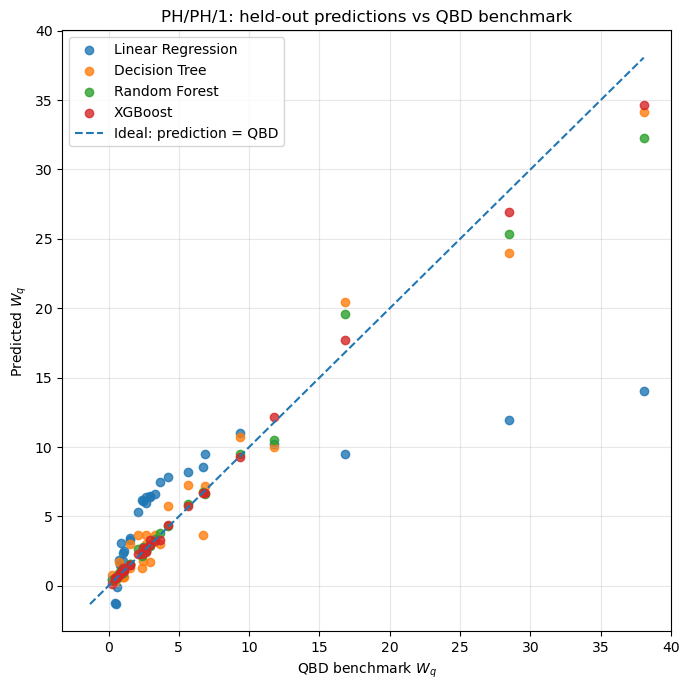

In [18]:
fig, ax = plt.subplots(figsize=(7, 7))

x = final_test_predictions["Wq_qbd"]

for model_name, short in short_names.items():
    ax.scatter(
        x,
        final_test_predictions[f"Wq_pred_{short}"],
        label=model_name,
        alpha=0.8,
    )

pred_cols = [f"Wq_pred_{short}" for short in short_names.values()]
lo = min(x.min(), final_test_predictions[pred_cols].min().min())
hi = max(x.max(), final_test_predictions[pred_cols].max().max())

ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    label="Ideal: prediction = QBD",
)

ax.set_xlabel(r"QBD benchmark $W_q$")
ax.set_ylabel(r"Predicted $W_q$")
ax.set_title("PH/PH/1: held-out predictions vs QBD benchmark")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "phph1_final_predicted_vs_qbd_Wq.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

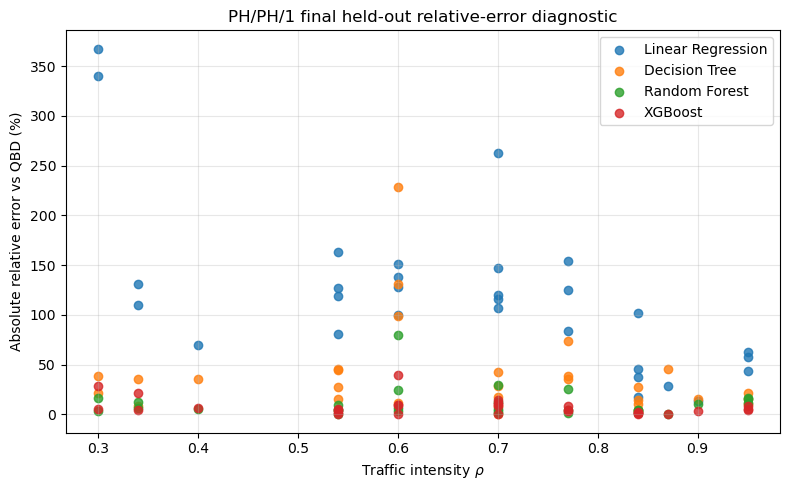

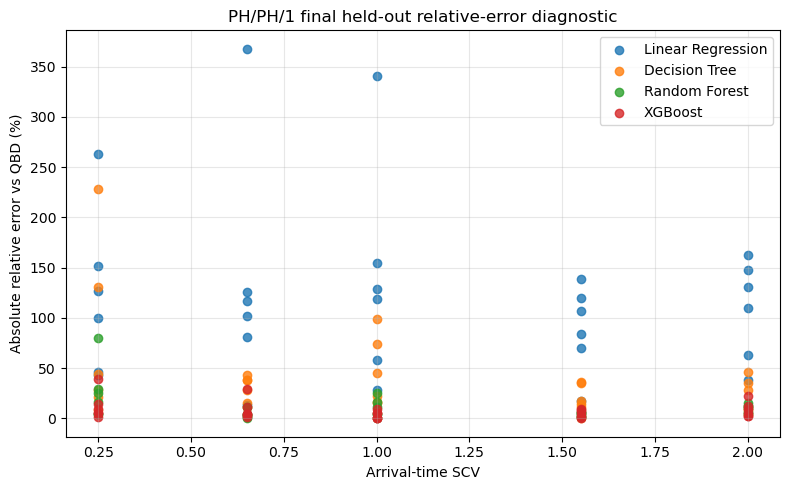

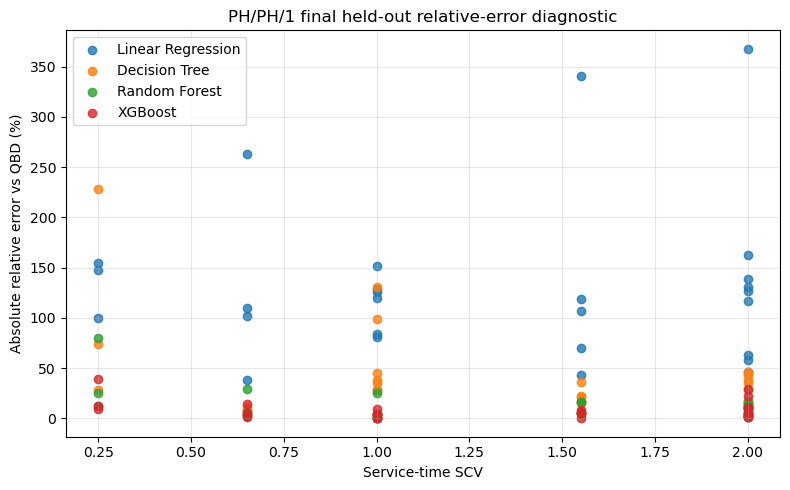

In [19]:
error_cols = {
    model_name: f"Wq_rel_error_pct_{short}_vs_qbd"
    for model_name, short in short_names.items()
}

for x_col, x_label, filename in [
    ("rho", r"Traffic intensity $\rho$", "phph1_error_vs_rho.png"),
    ("arrival_scv", "Arrival-time SCV", "phph1_error_vs_arrival_scv.png"),
    ("service_scv", "Service-time SCV", "phph1_error_vs_service_scv.png"),
]:
    fig, ax = plt.subplots(figsize=(8, 5))

    for model_name, error_col in error_cols.items():
        ax.scatter(
            final_test_predictions[x_col],
            final_test_predictions[error_col],
            label=model_name,
            alpha=0.8,
        )

    ax.set_xlabel(x_label)
    ax.set_ylabel("Absolute relative error vs QBD (%)")
    ax.set_title("PH/PH/1 final held-out relative-error diagnostic")
    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

## 12. Interpretation and decision points

The PH/PH/1 stage is a genuine structural extension of M/PH/1 because arrivals are no longer Poisson. The main mapping is now

\[
(\rho,\mathrm{SCV}_A,\mathrm{SCV}_S)\longrightarrow W_q.
\]

Recommended interpretation sequence:

1. **QBD sanity check:** confirm the implementation reproduces M/M/1 and the \(SCV_A=1\) M/PH/1 slice.
2. **Protocol-transfer check:** inspect error, confidence-interval width, and CI coverage across the 27 representative configurations.
3. **Formal label quality:** compare the full 300-configuration simulation labels with QBD.
4. **ML performance:** compare the same four regression models on the untouched test configurations.
5. **Cross-stage discussion:** do not compare raw M/PH/1 and PH/PH/1 RMSE values as if they were the same mathematical mapping. PH/PH/1 has an additional arrival-variability dimension and a different stationary surface.

### Important limitation

This notebook uses one canonical PH construction for each requested SCV. Therefore the three input descriptors uniquely specify the generated queue within this experiment.

For a broader PH/PH/1 study, two different PH distributions can share the same first two moments but still produce different queueing behaviour. A later extension should then add richer distributional descriptors, such as higher moments or features derived from \((\alpha,T)\). This becomes particularly important before MAP/PH/1, where arrival dependence introduces information that SCV alone cannot capture.

## 13. SCV-regime annotation of the completed combined PH/PH/1 experiment

The completed mixed-regime experiment is retained unchanged. This section adds explicit
SCV-regime labels for interpretation:

- `SCV < 1`: generalized-Erlang / sequential hypoexponential PH;
- `SCV = 1`: exponential boundary case;
- `SCV > 1`: two-phase hyperexponential PH.

Because PH/PH/1 has both arrival- and service-time variability, each configuration is
classified by the pair `(arrival_regime, service_regime)`. The four non-boundary joint
regimes are analysed separately later, while the `SCV=1` slices are retained as boundary
consistency cases.


In [20]:
def scv_regime(scv, tol=1e-10):
    """Return '<1', '=1', or '>1' for an SCV value."""
    x = float(scv)
    if abs(x - 1.0) <= tol:
        return "=1"
    return "<1" if x < 1.0 else ">1"


def add_scv_regime_columns(df):
    out = df.copy()
    out["arrival_regime"] = out["arrival_scv"].map(scv_regime)
    out["service_regime"] = out["service_scv"].map(scv_regime)
    out["joint_regime"] = (
        "A" + out["arrival_regime"] + "_S" + out["service_regime"]
    )
    return out


configuration_design = add_scv_regime_columns(configuration_design)
stationary_labels = add_scv_regime_columns(stationary_labels)
final_test_predictions = add_scv_regime_columns(final_test_predictions)

# Save annotated versions without overwriting the original completed outputs.
configuration_design.to_csv(
    OUTPUT_DIR / "phph1_configuration_design_300_regime_annotated.csv",
    index=False,
)
stationary_labels.to_csv(
    OUTPUT_DIR / "phph1_300_stationary_labels_regime_annotated.csv",
    index=False,
)
final_test_predictions.to_csv(
    OUTPUT_DIR / "phph1_final_test_predictions_regime_annotated.csv",
    index=False,
)

print("Combined-design regime counts:")
display(
    pd.crosstab(
        stationary_labels["arrival_regime"],
        stationary_labels["service_regime"],
        margins=True,
    )
)


Combined-design regime counts:


service_regime,<1,=1,>1,All
arrival_regime,,,,
<1,48,24,48,120
=1,24,12,24,60
>1,48,24,48,120
All,120,60,120,300


### 13.1 Combined-model held-out performance by joint SCV regime

This is a diagnostic of the already-completed mixed-regime model. It does **not** replace
the separate regime-specific experiments below. Because the original final test set contains
only 30 configurations, the number of test points in each joint regime is reported explicitly
and small-regime summaries should be interpreted cautiously.


In [21]:
NON_BOUNDARY_REGIMES = {
    "A<1_S<1": ("<1", "<1"),
    "A<1_S>1": ("<1", ">1"),
    "A>1_S<1": (">1", "<1"),
    "A>1_S>1": (">1", ">1"),
}

combined_joint_metric_rows = []
for joint_name, (a_regime, s_regime) in NON_BOUNDARY_REGIMES.items():
    g = final_test_predictions[
        (final_test_predictions["arrival_regime"] == a_regime)
        & (final_test_predictions["service_regime"] == s_regime)
    ].copy()

    if len(g) == 0:
        continue

    mean_qbd = float(g["Wq_qbd"].abs().mean())
    for model_name, short in short_names.items():
        metrics = regression_metrics(
            g["Wq_qbd"].to_numpy(),
            g[f"Wq_pred_{short}"].to_numpy(),
        )
        combined_joint_metric_rows.append({
            "joint_regime": joint_name,
            "n_test": len(g),
            "Model": model_name,
            **metrics,
            "NRMSE_mean_pct": 100.0 * metrics["RMSE"] / mean_qbd,
        })

combined_joint_metrics = pd.DataFrame(combined_joint_metric_rows)
combined_joint_metrics.to_csv(
    OUTPUT_DIR / "phph1_combined_model_metrics_by_joint_regime.csv",
    index=False,
)

display(
    combined_joint_metrics[
        [
            "joint_regime", "n_test", "Model", "MAE", "RMSE",
            "NRMSE_mean_pct", "R2", "MAPE_pct", "Median_APE_pct",
        ]
    ].round(6)
)


,joint_regime,n_test,Model,MAE,RMSE,NRMSE_mean_pct,R2,MAPE_pct,Median_APE_pct
0,A<1_S<1,3,Linear Regression,1.948965,2.336965,160.007612,-2.158864,155.046435,102.048677
1,A<1_S<1,3,Decision Tree,0.325190,0.378277,25.899905,0.917235,82.688010,10.840599
2,A<1_S<1,3,Random Forest,0.185460,0.193840,13.271869,0.978267,37.535589,29.382411
3,A<1_S<1,3,XGBoost,0.087868,0.094021,6.437439,0.994887,18.424149,14.646932
4,A<1_S>1,6,Linear Regression,3.001324,3.638481,56.246787,0.628466,118.875196,80.979221
5,A<1_S>1,6,Decision Tree,1.488203,1.857329,28.712199,0.903186,31.721742,33.183581
6,A<1_S>1,6,Random Forest,0.733583,1.254476,19.392772,0.955835,6.708525,4.189758
7,A<1_S>1,6,XGBoost,0.302744,0.403862,6.243244,0.995423,9.146163,5.343889
8,A>1_S<1,3,Linear Regression,2.310712,2.618152,78.927829,0.007312,98.482481,109.596756
9,A>1_S<1,3,Decision Tree,0.355813,0.442972,13.354000,0.971583,13.870393,8.715076


## 14. PH/PH/1 dataset-size adequacy check

The combined PH/PH/1 task has three predictors, `(rho, SCV_A, SCV_S)`, rather than the
two-input M/PH/1 task. Therefore the working sample size is reassessed at the PH/PH/1 stage.

The original 30 validation and 30 final-test configurations remain fixed. Only training
coverage is expanded:

- 300 total = 240 train + 30 validation + 30 test;
- 400 total = 340 train + 30 validation + 30 test;
- 500 total = 440 train + 30 validation + 30 test.

Each additional 100-point training batch is regime-balanced: 80 points are allocated evenly
across the four non-boundary joint regimes and 20 points across the four one-boundary slices.
The final test set is not used in dataset-size or hyperparameter decisions.


In [22]:
RUN_DATASET_SIZE_ADEQUACY = True

LOW_SCV_RANGE = (0.25, 0.95)
HIGH_SCV_RANGE = (1.05, 2.00)


def stratified_continuous_sample(n, low, high, rng):
    """One random point from each of n equal-width intervals."""
    u = (np.arange(n) + rng.random(n)) / n
    rng.shuffle(u)
    return low + (high - low) * u


def _balanced_group_points(n, arrival_spec, service_spec, rng):
    rho = stratified_continuous_sample(n, 0.30, 0.95, rng)

    if arrival_spec == "low":
        a = stratified_continuous_sample(n, *LOW_SCV_RANGE, rng)
    elif arrival_spec == "high":
        a = stratified_continuous_sample(n, *HIGH_SCV_RANGE, rng)
    elif arrival_spec == "boundary":
        a = np.ones(n)
    else:
        raise ValueError(arrival_spec)

    if service_spec == "low":
        s = stratified_continuous_sample(n, *LOW_SCV_RANGE, rng)
    elif service_spec == "high":
        s = stratified_continuous_sample(n, *HIGH_SCV_RANGE, rng)
    elif service_spec == "boundary":
        s = np.ones(n)
    else:
        raise ValueError(service_spec)

    # Break any artificial monotone pairing among rho / arrival SCV / service SCV.
    rng.shuffle(a)
    rng.shuffle(s)

    return pd.DataFrame({
        "rho": np.round(rho, 6),
        "arrival_scv": np.round(a, 6),
        "service_scv": np.round(s, 6),
    })


def make_additional_training_batch(batch_id, seed, seed_namespace):
    """Create exactly 100 new regime-balanced training configurations."""
    rng = np.random.default_rng(seed)
    parts = []

    # Four non-boundary joint regimes: 20 each = 80.
    for a_spec, s_spec in [
        ("low", "low"),
        ("low", "high"),
        ("high", "low"),
        ("high", "high"),
    ]:
        parts.append(_balanced_group_points(20, a_spec, s_spec, rng))

    # Four one-boundary slices: 5 each = 20.
    for a_spec, s_spec in [
        ("boundary", "low"),
        ("boundary", "high"),
        ("low", "boundary"),
        ("high", "boundary"),
    ]:
        parts.append(_balanced_group_points(5, a_spec, s_spec, rng))

    d = pd.concat(parts, ignore_index=True)
    assert len(d) == 100

    d.insert(
        0,
        "config_id",
        [f"size{batch_id}_extra_{i:03d}" for i in range(len(d))],
    )
    d["split"] = "train"
    d["design_batch"] = f"additional_training_batch_{batch_id}"
    d["stream_id"] = np.arange(len(d), dtype=int)
    d["seed_namespace"] = int(seed_namespace)
    d["rho_band"] = pd.cut(
        d["rho"],
        bins=[0.299, 0.50, 0.75, 0.90, 0.951],
        labels=["low", "moderate", "high", "very_high"],
        include_lowest=True,
    )
    d = add_scv_regime_columns(d)

    # Continuous sampling plus distinct namespaces makes accidental overlap unlikely;
    # still assert no within-batch duplicate parameter triples.
    assert not d.duplicated(["rho", "arrival_scv", "service_scv"]).any()
    return d


additional_100_design = make_additional_training_batch(
    batch_id=400,
    seed=BASE_SEED + 1400,
    seed_namespace=30,
)
additional_200_design = make_additional_training_batch(
    batch_id=500,
    seed=BASE_SEED + 1500,
    seed_namespace=31,
)

# Check against the completed 300-point design and against each other.
base_triples = set(map(tuple, configuration_design[["rho", "arrival_scv", "service_scv"]].round(6).to_numpy()))
extra100_triples = set(map(tuple, additional_100_design[["rho", "arrival_scv", "service_scv"]].round(6).to_numpy()))
extra200_triples = set(map(tuple, additional_200_design[["rho", "arrival_scv", "service_scv"]].round(6).to_numpy()))
assert base_triples.isdisjoint(extra100_triples)
assert base_triples.isdisjoint(extra200_triples)
assert extra100_triples.isdisjoint(extra200_triples)

additional_100_design.to_csv(
    OUTPUT_DIR / "phph1_dataset_size_extra100_design.csv", index=False
)
additional_200_design.to_csv(
    OUTPUT_DIR / "phph1_dataset_size_extra200_design.csv", index=False
)

display(pd.crosstab(additional_100_design["arrival_regime"], additional_100_design["service_regime"]))


service_regime,<1,=1,>1
arrival_regime,,,
<1,20,5,20
=1,5,0,5
>1,20,5,20


In [23]:
def validation_search_generic(
    model_name,
    candidate_params,
    X_train_local,
    y_train_local,
    X_val_local,
    y_val_local,
    random_state=BASE_SEED,
):
    rows = []
    predictions = {}

    for candidate_id, params in enumerate(candidate_params):
        if model_name == "Decision Tree":
            model = DecisionTreeRegressor(random_state=random_state, **params)
        elif model_name == "Random Forest":
            model = RandomForestRegressor(
                random_state=random_state, n_jobs=-1, **params
            )
        elif model_name == "XGBoost":
            model = XGBRegressor(
                random_state=random_state,
                objective="reg:squarederror",
                n_jobs=-1,
                verbosity=0,
                **params,
            )
        else:
            raise ValueError(model_name)

        start = time.perf_counter()
        model.fit(X_train_local, y_train_local)
        fit_seconds = time.perf_counter() - start
        pred = model.predict(X_val_local)
        val_rmse = rmse(y_val_local, pred)

        rows.append({
            "candidate_id": candidate_id,
            **params,
            "validation_RMSE_vs_sim_label": val_rmse,
            "training_seconds": fit_seconds,
        })
        predictions[candidate_id] = pred

    result = pd.DataFrame(rows).sort_values(
        "validation_RMSE_vs_sim_label"
    ).reset_index(drop=True)
    best_id = int(result.iloc[0]["candidate_id"])
    return result, predictions[best_id]


def run_dataset_size_validation(train_local, val_local, total_size):
    Xtr = train_local[feature_cols]
    ytr = train_local[target_col]
    Xv = val_local[feature_cols]
    yv = val_local[target_col]

    rows = []
    val_predictions = {}

    lr_local = LinearRegression().fit(Xtr, ytr)
    pred_lr = lr_local.predict(Xv)
    rows.append({
        "total_design_size": total_size,
        "n_train": len(train_local),
        "Model": "Linear Regression",
        "validation_RMSE_vs_sim_label": rmse(yv, pred_lr),
        "best_params": "raw inputs; no tuning",
    })
    val_predictions["Linear Regression"] = pred_lr

    for model_name, candidates in [
        ("Decision Tree", dt_candidates),
        ("Random Forest", rf_candidates),
        ("XGBoost", xgb_candidates),
    ]:
        search, best_pred = validation_search_generic(
            model_name,
            candidates,
            Xtr,
            ytr,
            Xv,
            yv,
            random_state=BASE_SEED + int(total_size),
        )
        best = search.iloc[0]
        param_cols = [c for c in candidates[0].keys() if c in best.index]
        best_params = {c: best[c] for c in param_cols}
        rows.append({
            "total_design_size": total_size,
            "n_train": len(train_local),
            "Model": model_name,
            "validation_RMSE_vs_sim_label": float(best["validation_RMSE_vs_sim_label"]),
            "best_params": json.dumps(best_params, default=float),
        })
        val_predictions[model_name] = best_pred

    return pd.DataFrame(rows), val_predictions


Generating the first 100 additional PH/PH/1 training labels...
[1/100] size400_extra_000 rho=0.54, SCV_A=0.39, SCV_S=0.30
[25/100] size400_extra_024 rho=0.71, SCV_A=0.89, SCV_S=1.16
[50/100] size400_extra_049 rho=0.38, SCV_A=1.24, SCV_S=0.75
[75/100] size400_extra_074 rho=0.62, SCV_A=1.67, SCV_S=1.49
[100/100] size400_extra_099 rho=0.81, SCV_A=1.79, SCV_S=1.00
Full label generation completed in 0.08 minutes.
Generating the second 100 additional PH/PH/1 training labels...
[1/100] size500_extra_000 rho=0.64, SCV_A=0.69, SCV_S=0.39
[25/100] size500_extra_024 rho=0.95, SCV_A=0.78, SCV_S=1.12
[50/100] size500_extra_049 rho=0.59, SCV_A=1.10, SCV_S=0.74
[75/100] size500_extra_074 rho=0.86, SCV_A=1.70, SCV_S=1.77
[100/100] size500_extra_099 rho=0.91, SCV_A=1.85, SCV_S=1.00
Full label generation completed in 0.08 minutes.


,total_design_size,n_train,Model,validation_RMSE_vs_sim_label,best_params
0,300,240,Linear Regression,4.056715,raw inputs; no tuning
1,300,240,Decision Tree,1.606708,"{""max_depth"": 5.0, ""min_samples_leaf"": 1.0}"
2,300,240,Random Forest,0.555684,"{""n_estimators"": 300.0, ""max_depth"": NaN, ""min..."
3,300,240,XGBoost,0.429271,"{""n_estimators"": 250.0, ""max_depth"": 3.0, ""lea..."
4,400,340,Linear Regression,4.092885,raw inputs; no tuning
5,400,340,Decision Tree,1.569892,"{""max_depth"": 5.0, ""min_samples_leaf"": 1.0}"
6,400,340,Random Forest,0.695072,"{""n_estimators"": 300.0, ""max_depth"": 8.0, ""min..."
7,400,340,XGBoost,0.386929,"{""n_estimators"": 400.0, ""max_depth"": 3.0, ""lea..."
8,500,440,Linear Regression,4.124585,raw inputs; no tuning
9,500,440,Decision Tree,1.836824,"{""max_depth"": 6.0, ""min_samples_leaf"": 1.0}"


,Model,from_total_size,to_total_size,validation_prediction_shift_RMSE
0,Linear Regression,300,400,0.437811
1,Decision Tree,300,400,1.717998
2,Random Forest,300,400,0.247505
3,XGBoost,300,400,0.107575
4,Linear Regression,400,500,0.194767
5,Decision Tree,400,500,0.814328
6,Random Forest,400,500,0.135447
7,XGBoost,400,500,0.215231


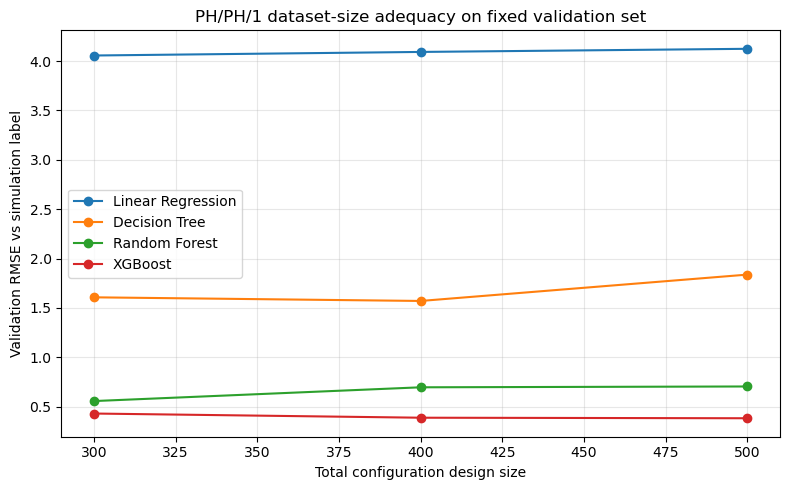

In [24]:
if RUN_DATASET_SIZE_ADEQUACY:
    print("Generating the first 100 additional PH/PH/1 training labels...")
    size_extra100_replications = generate_full_replication_dataset(additional_100_design)
    size_extra100_labels = aggregate_configuration_labels(size_extra100_replications)
    size_extra100_labels = size_extra100_labels.merge(
        additional_100_design[
            [
                "config_id", "split", "design_batch", "rho_band",
                "arrival_regime", "service_regime", "joint_regime",
                "stream_id", "seed_namespace",
            ]
        ],
        on="config_id",
        how="left",
        validate="one_to_one",
    )

    print("Generating the second 100 additional PH/PH/1 training labels...")
    size_extra200_replications = generate_full_replication_dataset(additional_200_design)
    size_extra200_labels = aggregate_configuration_labels(size_extra200_replications)
    size_extra200_labels = size_extra200_labels.merge(
        additional_200_design[
            [
                "config_id", "split", "design_batch", "rho_band",
                "arrival_regime", "service_regime", "joint_regime",
                "stream_id", "seed_namespace",
            ]
        ],
        on="config_id",
        how="left",
        validate="one_to_one",
    )

    # Random-number streams must remain disjoint from the original formal run.
    assert set(size_extra100_replications["seed"]).isdisjoint(set(full_replications["seed"]))
    assert set(size_extra200_replications["seed"]).isdisjoint(set(full_replications["seed"]))
    assert set(size_extra100_replications["seed"]).isdisjoint(set(size_extra200_replications["seed"]))

    size_extra100_replications.to_csv(
        OUTPUT_DIR / "phph1_dataset_size_extra100_replications.csv", index=False
    )
    size_extra100_labels.to_csv(
        OUTPUT_DIR / "phph1_dataset_size_extra100_labels.csv", index=False
    )
    size_extra200_replications.to_csv(
        OUTPUT_DIR / "phph1_dataset_size_extra200_replications.csv", index=False
    )
    size_extra200_labels.to_csv(
        OUTPUT_DIR / "phph1_dataset_size_extra200_labels.csv", index=False
    )

    fixed_base_train = stationary_labels[stationary_labels["split"] == "train"].copy()
    fixed_val = stationary_labels[stationary_labels["split"] == "validation"].copy()
    fixed_test = stationary_labels[stationary_labels["split"] == "test"].copy()

    nested_training_sets = {
        300: fixed_base_train,
        400: pd.concat([fixed_base_train, size_extra100_labels], ignore_index=True),
        500: pd.concat(
            [fixed_base_train, size_extra100_labels, size_extra200_labels],
            ignore_index=True,
        ),
    }

    adequacy_rows = []
    adequacy_predictions = {}
    for total_size, train_local in nested_training_sets.items():
        metrics_local, preds_local = run_dataset_size_validation(
            train_local,
            fixed_val,
            total_size,
        )
        adequacy_rows.append(metrics_local)
        adequacy_predictions[total_size] = preds_local

    dataset_size_adequacy = pd.concat(adequacy_rows, ignore_index=True)

    # Prediction-shift diagnostic between adjacent design sizes on the same validation set.
    shift_rows = []
    for previous_size, current_size in [(300, 400), (400, 500)]:
        for model_name in short_names.keys():
            shift_rows.append({
                "Model": model_name,
                "from_total_size": previous_size,
                "to_total_size": current_size,
                "validation_prediction_shift_RMSE": rmse(
                    adequacy_predictions[previous_size][model_name],
                    adequacy_predictions[current_size][model_name],
                ),
            })
    dataset_size_prediction_shift = pd.DataFrame(shift_rows)

    dataset_size_adequacy.to_csv(
        OUTPUT_DIR / "phph1_dataset_size_adequacy_validation.csv", index=False
    )
    dataset_size_prediction_shift.to_csv(
        OUTPUT_DIR / "phph1_dataset_size_prediction_shift.csv", index=False
    )

    display(dataset_size_adequacy.round(6))
    display(dataset_size_prediction_shift.round(6))

    fig, ax = plt.subplots(figsize=(8, 5))
    for model_name in short_names.keys():
        g = dataset_size_adequacy[
            dataset_size_adequacy["Model"] == model_name
        ].sort_values("total_design_size")
        ax.plot(
            g["total_design_size"],
            g["validation_RMSE_vs_sim_label"],
            marker="o",
            label=model_name,
        )
    ax.set_xlabel("Total configuration design size")
    ax.set_ylabel("Validation RMSE vs simulation label")
    ax.set_title("PH/PH/1 dataset-size adequacy on fixed validation set")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / "phph1_dataset_size_adequacy.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
else:
    print("Dataset-size adequacy run skipped. Set RUN_DATASET_SIZE_ADEQUACY=True to run it.")


## 15. Boundary / consistency cases at `SCV = 1`

`SCV=1` is treated as a boundary rather than as a fifth regime-specific ML experiment.
The three relevant reductions are:

- `SCV_A = 1`: PH/PH/1 reduces to M/PH/1, so QBD can be checked against the exact PK mean;
- `SCV_S = 1`: PH/PH/1 becomes PH/M/1 (exponential service); the QBD benchmark remains the reference;
- `SCV_A = SCV_S = 1`: the system reduces to M/M/1 and can be checked against the exact M/M/1 mean waiting time.

The already-completed combined 300-point dataset contains all of these slices, so no new
large ML dataset is required for the boundary cases.


In [25]:
boundary_rows = []

# A-SCV = 1 -> M/PH/1: compare QBD to exact PK.
a_eq1 = stationary_labels[np.isclose(stationary_labels["arrival_scv"], 1.0)].copy()
a_eq1["exact_reference"] = (
    a_eq1["rho"] * (1.0 + a_eq1["service_scv"])
    / (2.0 * (1.0 - a_eq1["rho"]))
)
a_eq1["QBD_minus_exact_abs"] = (a_eq1["Wq_qbd"] - a_eq1["exact_reference"]).abs()
boundary_rows.append({
    "boundary_case": "SCV_A=1 -> M/PH/1",
    "n_configurations": len(a_eq1),
    "max_abs_QBD_minus_exact": a_eq1["QBD_minus_exact_abs"].max(),
    "mean_sim_rel_error_vs_QBD_pct": a_eq1["Wq_rel_error_vs_qbd_pct"].mean(),
    "ci95_coverage_vs_QBD_pct": 100.0 * a_eq1["CI_contains_qbd"].mean(),
})

# S-SCV = 1 -> PH/M/1: QBD remains the benchmark; report simulation agreement.
s_eq1 = stationary_labels[np.isclose(stationary_labels["service_scv"], 1.0)].copy()
boundary_rows.append({
    "boundary_case": "SCV_S=1 -> PH/M/1",
    "n_configurations": len(s_eq1),
    "max_abs_QBD_minus_exact": np.nan,
    "mean_sim_rel_error_vs_QBD_pct": s_eq1["Wq_rel_error_vs_qbd_pct"].mean(),
    "ci95_coverage_vs_QBD_pct": 100.0 * s_eq1["CI_contains_qbd"].mean(),
})

# Both equal 1 -> M/M/1: compare QBD to exact M/M/1 formula.
both_eq1 = stationary_labels[
    np.isclose(stationary_labels["arrival_scv"], 1.0)
    & np.isclose(stationary_labels["service_scv"], 1.0)
].copy()
both_eq1["exact_reference"] = both_eq1["rho"] / (1.0 - both_eq1["rho"])
both_eq1["QBD_minus_exact_abs"] = (
    both_eq1["Wq_qbd"] - both_eq1["exact_reference"]
).abs()
boundary_rows.append({
    "boundary_case": "SCV_A=SCV_S=1 -> M/M/1",
    "n_configurations": len(both_eq1),
    "max_abs_QBD_minus_exact": both_eq1["QBD_minus_exact_abs"].max(),
    "mean_sim_rel_error_vs_QBD_pct": both_eq1["Wq_rel_error_vs_qbd_pct"].mean(),
    "ci95_coverage_vs_QBD_pct": 100.0 * both_eq1["CI_contains_qbd"].mean(),
})

boundary_consistency_summary = pd.DataFrame(boundary_rows)
boundary_consistency_summary.to_csv(
    OUTPUT_DIR / "phph1_boundary_consistency_summary.csv",
    index=False,
)

a_eq1.to_csv(OUTPUT_DIR / "phph1_boundary_arrival_scv_eq1.csv", index=False)
s_eq1.to_csv(OUTPUT_DIR / "phph1_boundary_service_scv_eq1.csv", index=False)
both_eq1.to_csv(OUTPUT_DIR / "phph1_boundary_both_scv_eq1.csv", index=False)

display(boundary_consistency_summary.round(8))

assert a_eq1["QBD_minus_exact_abs"].max() < 1e-7
assert both_eq1["QBD_minus_exact_abs"].max() < 1e-7


,boundary_case,n_configurations,max_abs_QBD_minus_exact,mean_sim_rel_error_vs_QBD_pct,ci95_coverage_vs_QBD_pct
0,SCV_A=1 -> M/PH/1,60,2.000000e-08,0.960639,95.000000
1,SCV_S=1 -> PH/M/1,60,NaN,1.192038,86.666667
2,SCV_A=SCV_S=1 -> M/M/1,12,1.000000e-08,1.117468,83.333333


## 16. Four non-boundary joint SCV-regime experiments

Four separate 300-configuration experiments are added:

1. `SCV_A < 1`, `SCV_S < 1` — hypo / hypo;
2. `SCV_A < 1`, `SCV_S > 1` — hypo / hyper;
3. `SCV_A > 1`, `SCV_S < 1` — hyper / hypo;
4. `SCV_A > 1`, `SCV_S > 1` — hyper / hyper.

Each regime uses the same 12 utilisation values and a direct `12 x 5 x 5 = 300` grid.
The 300 points are split into 240 train + 30 validation + 30 held-out test configurations.
The same simulation protocol, QBD benchmark, four ML methods, validation-only tuning, and
held-out evaluation are used in every regime. This makes the regime comparison controlled
while keeping the original mixed-regime experiment intact.


In [26]:
RUN_REGIME_EXPERIMENTS = True

REGIME_LOW_GRID_5 = np.round(np.linspace(0.25, 0.95, 5), 4)
REGIME_HIGH_GRID_5 = np.round(np.linspace(1.05, 2.00, 5), 4)

JOINT_REGIME_SPECS = {
    "lt1_lt1": {
        "arrival_grid": REGIME_LOW_GRID_5,
        "service_grid": REGIME_LOW_GRID_5,
        "label": "SCV_A<1, SCV_S<1",
        "seed_namespace": 41,
    },
    "lt1_gt1": {
        "arrival_grid": REGIME_LOW_GRID_5,
        "service_grid": REGIME_HIGH_GRID_5,
        "label": "SCV_A<1, SCV_S>1",
        "seed_namespace": 42,
    },
    "gt1_lt1": {
        "arrival_grid": REGIME_HIGH_GRID_5,
        "service_grid": REGIME_LOW_GRID_5,
        "label": "SCV_A>1, SCV_S<1",
        "seed_namespace": 43,
    },
    "gt1_gt1": {
        "arrival_grid": REGIME_HIGH_GRID_5,
        "service_grid": REGIME_HIGH_GRID_5,
        "label": "SCV_A>1, SCV_S>1",
        "seed_namespace": 44,
    },
}


def make_joint_regime_design(regime_key, spec):
    d = (
        pd.MultiIndex.from_product(
            [RHO_GRID_12, spec["arrival_grid"], spec["service_grid"]],
            names=["rho", "arrival_scv", "service_scv"],
        )
        .to_frame(index=False)
    )
    d.insert(
        0,
        "config_id",
        [f"{regime_key}_{i:03d}" for i in range(len(d))],
    )
    assert len(d) == 300

    d = add_scv_regime_columns(d)
    expected_a = "<1" if regime_key.startswith("lt1") else ">1"
    expected_s = "<1" if regime_key.endswith("lt1") else ">1"
    assert d["arrival_regime"].eq(expected_a).all()
    assert d["service_regime"].eq(expected_s).all()

    # Stratify by the 25 SCV-pair cells. Each cell contains the 12 rho values.
    d["scv_pair_stratum"] = (
        d["arrival_scv"].map(lambda x: f"A{x:.4f}")
        + "_"
        + d["service_scv"].map(lambda x: f"S{x:.4f}")
    )

    train_val, test = train_test_split(
        d,
        test_size=30,
        random_state=BASE_SEED + spec["seed_namespace"] * 10,
        stratify=d["scv_pair_stratum"],
    )
    train, validation = train_test_split(
        train_val,
        test_size=30,
        random_state=BASE_SEED + spec["seed_namespace"] * 10 + 1,
        stratify=train_val["scv_pair_stratum"],
    )

    d["split"] = ""
    d.loc[d["config_id"].isin(train["config_id"]), "split"] = "train"
    d.loc[d["config_id"].isin(validation["config_id"]), "split"] = "validation"
    d.loc[d["config_id"].isin(test["config_id"]), "split"] = "test"

    counts = d["split"].value_counts()
    assert counts["train"] == 240
    assert counts["validation"] == 30
    assert counts["test"] == 30

    d["rho_band"] = pd.cut(
        d["rho"],
        bins=[0.299, 0.50, 0.75, 0.90, 0.951],
        labels=["low", "moderate", "high", "very_high"],
        include_lowest=True,
    )
    d["design_batch"] = f"joint_regime_{regime_key}_direct300"
    d["stream_id"] = np.arange(len(d), dtype=int)
    d["seed_namespace"] = int(spec["seed_namespace"])
    return d


joint_regime_designs = {
    key: make_joint_regime_design(key, spec)
    for key, spec in JOINT_REGIME_SPECS.items()
}

for key, d in joint_regime_designs.items():
    d.to_csv(
        OUTPUT_DIR / f"phph1_{key}_configuration_design_300.csv",
        index=False,
    )
    print(key, d["split"].value_counts().to_dict())


lt1_lt1 {'train': 240, 'test': 30, 'validation': 30}
lt1_gt1 {'train': 240, 'test': 30, 'validation': 30}
gt1_lt1 {'train': 240, 'validation': 30, 'test': 30}
gt1_gt1 {'train': 240, 'test': 30, 'validation': 30}


In [27]:
def simulation_quality_summary(labels_df):
    return {
        "n_configurations": len(labels_df),
        "mean_relative_error_pct": labels_df["Wq_rel_error_vs_qbd_pct"].mean(),
        "median_relative_error_pct": labels_df["Wq_rel_error_vs_qbd_pct"].median(),
        "p90_relative_error_pct": labels_df["Wq_rel_error_vs_qbd_pct"].quantile(0.90),
        "p95_relative_error_pct": labels_df["Wq_rel_error_vs_qbd_pct"].quantile(0.95),
        "ci95_coverage_pct": 100.0 * labels_df["CI_contains_qbd"].mean(),
        "mean_relative_ci_halfwidth_pct": labels_df["Wq_relative_ci_halfwidth_pct"].mean(),
    }


def run_joint_regime_experiment(regime_key, spec, design_df):
    prefix = f"phph1_{regime_key}"

    print(f"\n===== Running {spec['label']} =====")
    replications = generate_full_replication_dataset(design_df)
    labels = aggregate_configuration_labels(replications)
    labels = labels.merge(
        design_df[
            [
                "config_id", "split", "rho_band", "design_batch",
                "arrival_regime", "service_regime", "joint_regime",
                "scv_pair_stratum", "stream_id", "seed_namespace",
            ]
        ],
        on="config_id",
        how="left",
        validate="one_to_one",
    )

    # The PH family must match the intended SCV regime on both sides.
    expected_arrival_family = (
        "generalized_erlang" if labels["arrival_regime"].iloc[0] == "<1"
        else "hyperexponential_2"
    )
    expected_service_family = (
        "generalized_erlang" if labels["service_regime"].iloc[0] == "<1"
        else "hyperexponential_2"
    )
    assert labels["arrival_ph_family"].eq(expected_arrival_family).all()
    assert labels["service_ph_family"].eq(expected_service_family).all()

    # Empirical input-process errors.
    labels["lambda_rel_error_pct"] = (
        100.0 * (labels["lambda_hat_mean"] - labels["lambda_rate"]).abs()
        / labels["lambda_rate"].abs()
    )
    labels["arrival_scv_rel_error_pct"] = (
        100.0 * (labels["arrival_scv_hat_mean"] - labels["arrival_scv"]).abs()
        / labels["arrival_scv"].abs()
    )
    labels["service_scv_rel_error_pct"] = (
        100.0 * (labels["service_scv_hat_mean"] - labels["service_scv"]).abs()
        / labels["service_scv"].abs()
    )

    input_summary = pd.DataFrame([{
        "regime": spec["label"],
        "n_configurations": len(labels),
        "mean_lambda_rel_error_pct": labels["lambda_rel_error_pct"].mean(),
        "max_lambda_rel_error_pct": labels["lambda_rel_error_pct"].max(),
        "mean_arrival_scv_rel_error_pct": labels["arrival_scv_rel_error_pct"].mean(),
        "max_arrival_scv_rel_error_pct": labels["arrival_scv_rel_error_pct"].max(),
        "mean_service_scv_rel_error_pct": labels["service_scv_rel_error_pct"].mean(),
        "max_service_scv_rel_error_pct": labels["service_scv_rel_error_pct"].max(),
    }])

    sim_summary = pd.DataFrame([{
        "regime": spec["label"],
        **simulation_quality_summary(labels),
    }])

    sim_by_rho = (
        labels.groupby("rho_band", observed=False)
        .agg(
            n_configurations=("config_id", "count"),
            mean_relative_error_pct=("Wq_rel_error_vs_qbd_pct", "mean"),
            p90_relative_error_pct=("Wq_rel_error_vs_qbd_pct", lambda x: x.quantile(0.90)),
            ci95_coverage_pct=("CI_contains_qbd", lambda x: 100.0 * x.mean()),
            mean_relative_ci_halfwidth_pct=("Wq_relative_ci_halfwidth_pct", "mean"),
        )
        .reset_index()
    )
    sim_by_rho.insert(0, "regime", spec["label"])

    # Split and tune on validation only.
    train_local = labels[labels["split"] == "train"].copy()
    val_local = labels[labels["split"] == "validation"].copy()
    test_local = labels[labels["split"] == "test"].copy()
    assert (len(train_local), len(val_local), len(test_local)) == (240, 30, 30)

    Xtr = train_local[feature_cols]
    ytr = train_local[target_col]
    Xv = val_local[feature_cols]
    yv = val_local[target_col]

    lr_local = LinearRegression().fit(Xtr, ytr)
    lr_val_rmse_local = rmse(yv, lr_local.predict(Xv))

    dt_search_local, _ = validation_search_generic(
        "Decision Tree", dt_candidates, Xtr, ytr, Xv, yv,
        random_state=BASE_SEED + spec["seed_namespace"],
    )
    rf_search_local, _ = validation_search_generic(
        "Random Forest", rf_candidates, Xtr, ytr, Xv, yv,
        random_state=BASE_SEED + spec["seed_namespace"],
    )
    xgb_search_local, _ = validation_search_generic(
        "XGBoost", xgb_candidates, Xtr, ytr, Xv, yv,
        random_state=BASE_SEED + spec["seed_namespace"],
    )

    best_dt_local = dt_search_local.iloc[0]
    best_rf_local = rf_search_local.iloc[0]
    best_xgb_local = xgb_search_local.iloc[0]

    dt_params_local = {
        "max_depth": None if pd.isna(best_dt_local["max_depth"]) else int(best_dt_local["max_depth"]),
        "min_samples_leaf": int(best_dt_local["min_samples_leaf"]),
    }
    rf_params_local = {
        "n_estimators": int(best_rf_local["n_estimators"]),
        "max_depth": None if pd.isna(best_rf_local["max_depth"]) else int(best_rf_local["max_depth"]),
        "min_samples_leaf": int(best_rf_local["min_samples_leaf"]),
    }
    xgb_params_local = {
        "n_estimators": int(best_xgb_local["n_estimators"]),
        "max_depth": int(best_xgb_local["max_depth"]),
        "learning_rate": float(best_xgb_local["learning_rate"]),
    }

    dev_local = pd.concat([train_local, val_local], ignore_index=True)
    Xdev = dev_local[feature_cols]
    ydev = dev_local[target_col]
    Xtest = test_local[feature_cols]
    ytest_sim = test_local[target_col].to_numpy()
    ytest_qbd = test_local["Wq_qbd"].to_numpy()

    models_local = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(
            random_state=BASE_SEED + spec["seed_namespace"], **dt_params_local
        ),
        "Random Forest": RandomForestRegressor(
            random_state=BASE_SEED + spec["seed_namespace"],
            n_jobs=-1,
            **rf_params_local,
        ),
        "XGBoost": XGBRegressor(
            random_state=BASE_SEED + spec["seed_namespace"],
            objective="reg:squarederror",
            n_jobs=-1,
            verbosity=0,
            **xgb_params_local,
        ),
    }

    final_preds_local = {}
    metric_rows = []
    timing_rows = []
    for model_name, model in models_local.items():
        start = time.perf_counter()
        model.fit(Xdev, ydev)
        train_seconds = time.perf_counter() - start

        start = time.perf_counter()
        pred = model.predict(Xtest)
        pred_seconds = time.perf_counter() - start
        final_preds_local[model_name] = pred

        metric_rows.append({
            "Regime": spec["label"],
            "Model": model_name,
            "Reference": "simulation mean label",
            **regression_metrics(ytest_sim, pred),
        })
        metric_rows.append({
            "Regime": spec["label"],
            "Model": model_name,
            "Reference": "QBD benchmark",
            **regression_metrics(ytest_qbd, pred),
        })
        timing_rows.append({
            "Regime": spec["label"],
            "Model": model_name,
            "training_seconds": train_seconds,
            "prediction_seconds_for_30_test_configs": pred_seconds,
        })

    metrics_local = pd.DataFrame(metric_rows)
    timing_local = pd.DataFrame(timing_rows)

    pred_df = test_local[
        [
            "config_id", "rho", "lambda_rate", "arrival_scv", "service_scv",
            "arrival_regime", "service_regime", "joint_regime",
            "arrival_ph_family", "service_ph_family",
            "Wq_sim_mean", "Wq_qbd", "Wq_ci95_low", "Wq_ci95_high",
            "Wq_relative_ci_halfwidth_pct", "Lq_qbd",
        ]
    ].copy()

    for model_name, pred in final_preds_local.items():
        short = short_names[model_name]
        pred_df[f"Wq_pred_{short}"] = pred
        pred_df[f"Lq_derived_pred_{short}"] = pred_df["lambda_rate"] * pred
        pred_df[f"Wq_abs_error_{short}_vs_qbd"] = (
            pred_df[f"Wq_pred_{short}"] - pred_df["Wq_qbd"]
        ).abs()
        pred_df[f"Wq_rel_error_pct_{short}_vs_qbd"] = (
            100.0 * pred_df[f"Wq_abs_error_{short}_vs_qbd"]
            / pred_df["Wq_qbd"].abs()
        )

    # Save tabular outputs.
    replications.to_csv(OUTPUT_DIR / f"{prefix}_300_replications.csv", index=False)
    labels.to_csv(OUTPUT_DIR / f"{prefix}_300_stationary_labels.csv", index=False)
    input_summary.to_csv(OUTPUT_DIR / f"{prefix}_input_validation_summary.csv", index=False)
    sim_summary.to_csv(OUTPUT_DIR / f"{prefix}_simulation_quality_summary.csv", index=False)
    sim_by_rho.to_csv(OUTPUT_DIR / f"{prefix}_simulation_quality_by_rho.csv", index=False)
    dt_search_local.to_csv(OUTPUT_DIR / f"{prefix}_dt_validation_search.csv", index=False)
    rf_search_local.to_csv(OUTPUT_DIR / f"{prefix}_rf_validation_search.csv", index=False)
    xgb_search_local.to_csv(OUTPUT_DIR / f"{prefix}_xgb_validation_search.csv", index=False)
    metrics_local.to_csv(OUTPUT_DIR / f"{prefix}_final_test_metrics.csv", index=False)
    timing_local.to_csv(OUTPUT_DIR / f"{prefix}_final_model_timing.csv", index=False)
    pred_df.to_csv(OUTPUT_DIR / f"{prefix}_final_test_predictions.csv", index=False)

    # Predicted vs QBD plot.
    fig, ax = plt.subplots(figsize=(7, 7))
    x = pred_df["Wq_qbd"]
    for model_name, short in short_names.items():
        ax.scatter(x, pred_df[f"Wq_pred_{short}"], label=model_name, alpha=0.8)
    pred_cols = [f"Wq_pred_{s}" for s in short_names.values()]
    lo = min(x.min(), pred_df[pred_cols].min().min())
    hi = max(x.max(), pred_df[pred_cols].max().max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", label="Ideal: prediction = QBD")
    ax.set_xlabel(r"QBD benchmark $W_q$")
    ax.set_ylabel(r"Predicted $W_q$")
    ax.set_title(f"PH/PH/1 {spec['label']}: held-out predictions")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{prefix}_predicted_vs_qbd_Wq.png", dpi=300, bbox_inches="tight")
    plt.show()

    # Error diagnostics.
    error_cols_local = {
        model_name: f"Wq_rel_error_pct_{short}_vs_qbd"
        for model_name, short in short_names.items()
    }
    for x_col, x_label, suffix in [
        ("rho", r"Traffic intensity $\rho$", "error_vs_rho.png"),
        ("arrival_scv", "Arrival-time SCV", "error_vs_arrival_scv.png"),
        ("service_scv", "Service-time SCV", "error_vs_service_scv.png"),
    ]:
        fig, ax = plt.subplots(figsize=(8, 5))
        for model_name, error_col in error_cols_local.items():
            ax.scatter(pred_df[x_col], pred_df[error_col], label=model_name, alpha=0.8)
        ax.set_xlabel(x_label)
        ax.set_ylabel("Absolute relative error vs QBD (%)")
        ax.set_title(f"PH/PH/1 {spec['label']}: held-out relative error")
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"{prefix}_{suffix}", dpi=300, bbox_inches="tight")
        plt.show()

    print(f"Linear Regression validation RMSE: {lr_val_rmse_local:.6f}")
    display(sim_summary.round(4))
    display(metrics_local.round(6))

    return {
        "design": design_df,
        "replications": replications,
        "labels": labels,
        "input_summary": input_summary,
        "simulation_summary": sim_summary,
        "simulation_by_rho": sim_by_rho,
        "dt_search": dt_search_local,
        "rf_search": rf_search_local,
        "xgb_search": xgb_search_local,
        "metrics": metrics_local,
        "timing": timing_local,
        "predictions": pred_df,
    }



===== Running SCV_A<1, SCV_S<1 =====
[1/300] lt1_lt1_000 rho=0.30, SCV_A=0.25, SCV_S=0.25
[25/300] lt1_lt1_024 rho=0.30, SCV_A=0.95, SCV_S=0.95
[50/300] lt1_lt1_049 rho=0.34, SCV_A=0.95, SCV_S=0.95
[75/300] lt1_lt1_074 rho=0.40, SCV_A=0.95, SCV_S=0.95
[100/300] lt1_lt1_099 rho=0.47, SCV_A=0.95, SCV_S=0.95
[125/300] lt1_lt1_124 rho=0.54, SCV_A=0.95, SCV_S=0.95
[150/300] lt1_lt1_149 rho=0.60, SCV_A=0.95, SCV_S=0.95
[175/300] lt1_lt1_174 rho=0.70, SCV_A=0.95, SCV_S=0.95
[200/300] lt1_lt1_199 rho=0.77, SCV_A=0.95, SCV_S=0.95
[225/300] lt1_lt1_224 rho=0.84, SCV_A=0.95, SCV_S=0.95
[250/300] lt1_lt1_249 rho=0.87, SCV_A=0.95, SCV_S=0.95
[275/300] lt1_lt1_274 rho=0.90, SCV_A=0.95, SCV_S=0.95
[300/300] lt1_lt1_299 rho=0.95, SCV_A=0.95, SCV_S=0.95
Full label generation completed in 0.22 minutes.


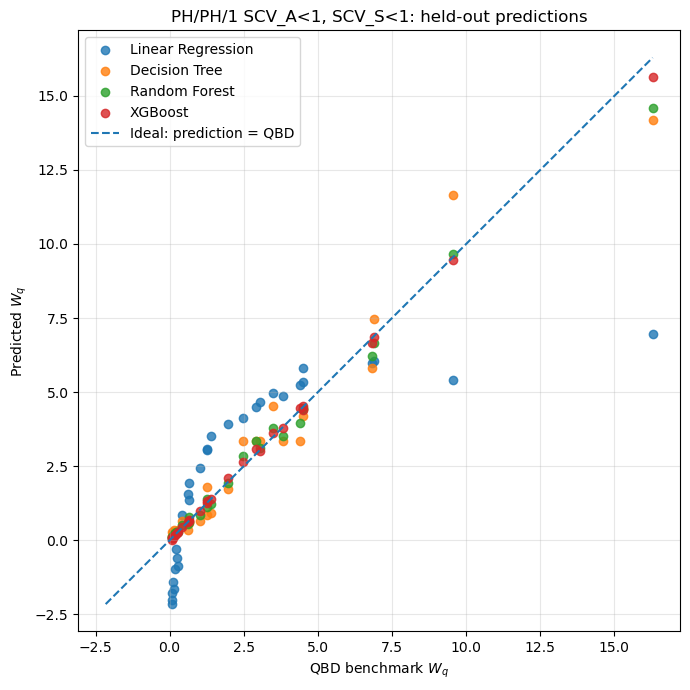

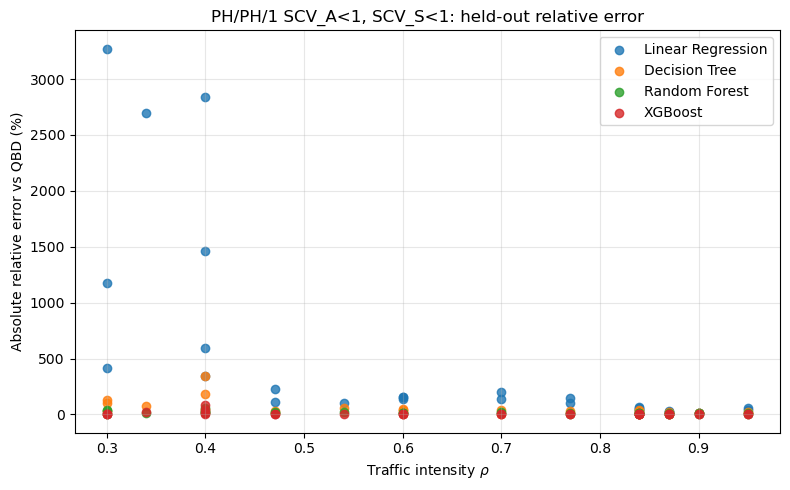

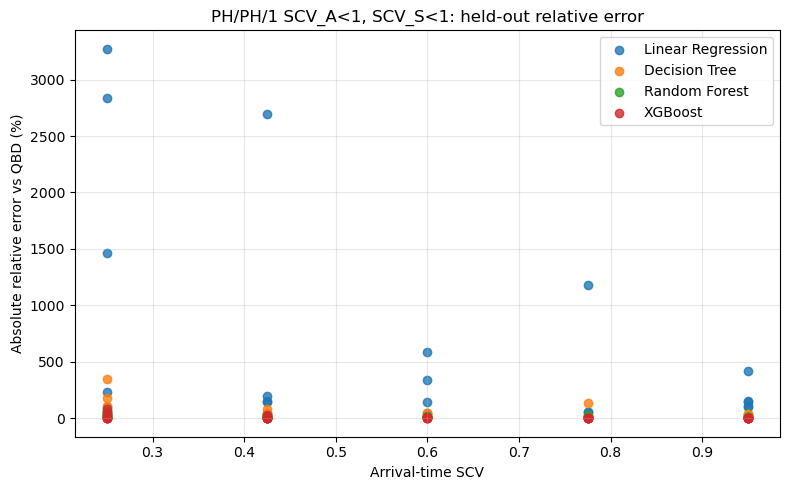

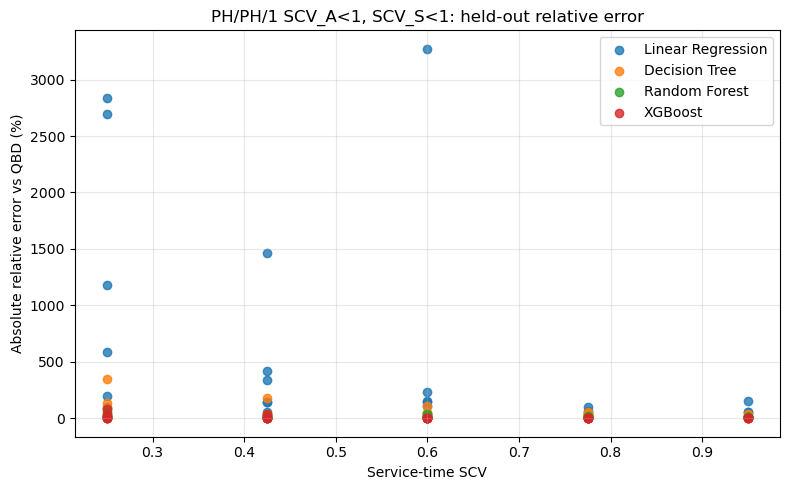

Linear Regression validation RMSE: 2.112663


,regime,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,p95_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,"SCV_A<1, SCV_S<1",300,0.8482,0.6611,1.8138,2.3608,93.0,2.1514


,Regime,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,"SCV_A<1, SCV_S<1",Linear Regression,simulation mean label,1.689565,2.284712,0.557216,489.972984,123.238311
1,"SCV_A<1, SCV_S<1",Linear Regression,QBD benchmark,1.704236,2.324118,0.553560,490.170893,123.831553
2,"SCV_A<1, SCV_S<1",Decision Tree,simulation mean label,0.445593,0.652042,0.963936,47.464591,28.724222
3,"SCV_A<1, SCV_S<1",Decision Tree,QBD benchmark,0.467543,0.707681,0.958608,47.726850,30.043450
4,"SCV_A<1, SCV_S<1",Random Forest,simulation mean label,0.176382,0.308058,0.991950,13.941661,9.871424
5,"SCV_A<1, SCV_S<1",Random Forest,QBD benchmark,0.198446,0.371387,0.988600,14.124072,10.209892
6,"SCV_A<1, SCV_S<1",XGBoost,simulation mean label,0.057434,0.092250,0.999278,7.610290,2.774586
7,"SCV_A<1, SCV_S<1",XGBoost,QBD benchmark,0.070825,0.137984,0.998426,7.711482,3.143222



===== Running SCV_A<1, SCV_S>1 =====
[1/300] lt1_gt1_000 rho=0.30, SCV_A=0.25, SCV_S=1.05
[25/300] lt1_gt1_024 rho=0.30, SCV_A=0.95, SCV_S=2.00
[50/300] lt1_gt1_049 rho=0.34, SCV_A=0.95, SCV_S=2.00
[75/300] lt1_gt1_074 rho=0.40, SCV_A=0.95, SCV_S=2.00
[100/300] lt1_gt1_099 rho=0.47, SCV_A=0.95, SCV_S=2.00
[125/300] lt1_gt1_124 rho=0.54, SCV_A=0.95, SCV_S=2.00
[150/300] lt1_gt1_149 rho=0.60, SCV_A=0.95, SCV_S=2.00
[175/300] lt1_gt1_174 rho=0.70, SCV_A=0.95, SCV_S=2.00
[200/300] lt1_gt1_199 rho=0.77, SCV_A=0.95, SCV_S=2.00
[225/300] lt1_gt1_224 rho=0.84, SCV_A=0.95, SCV_S=2.00
[250/300] lt1_gt1_249 rho=0.87, SCV_A=0.95, SCV_S=2.00
[275/300] lt1_gt1_274 rho=0.90, SCV_A=0.95, SCV_S=2.00
[300/300] lt1_gt1_299 rho=0.95, SCV_A=0.95, SCV_S=2.00
Full label generation completed in 0.25 minutes.


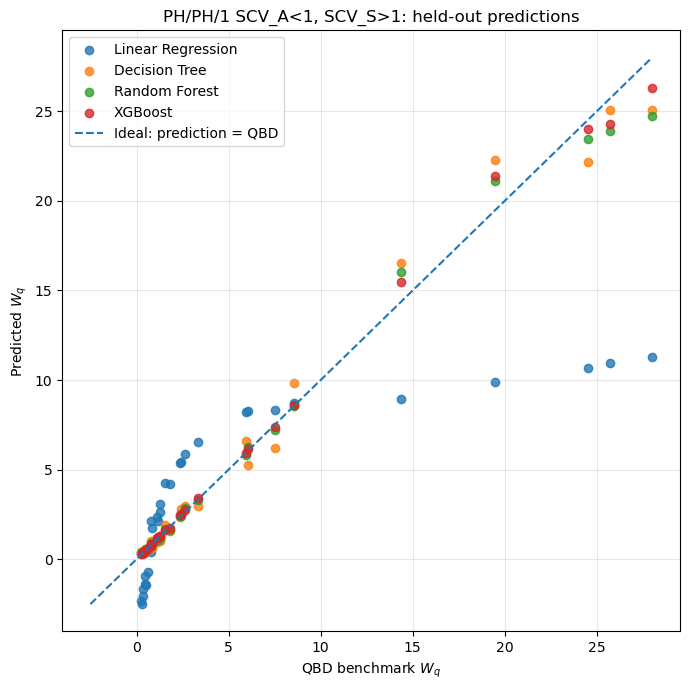

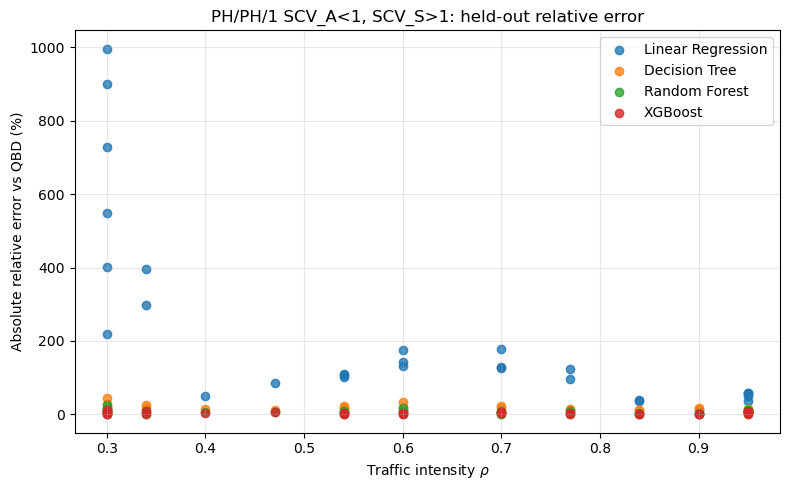

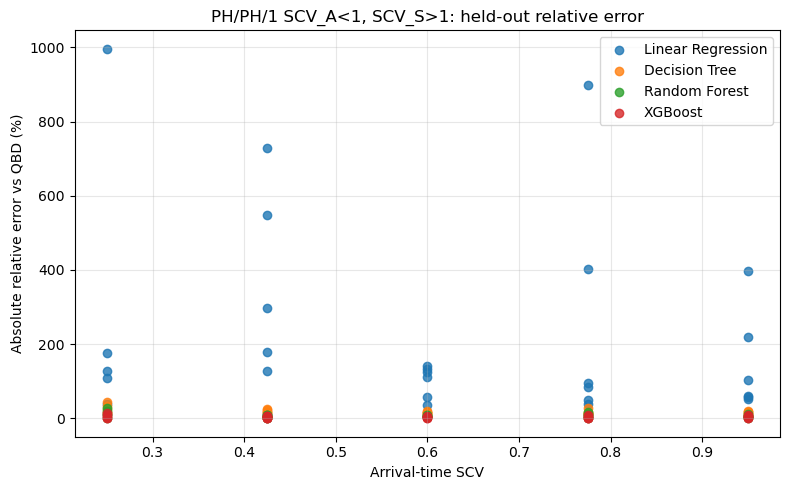

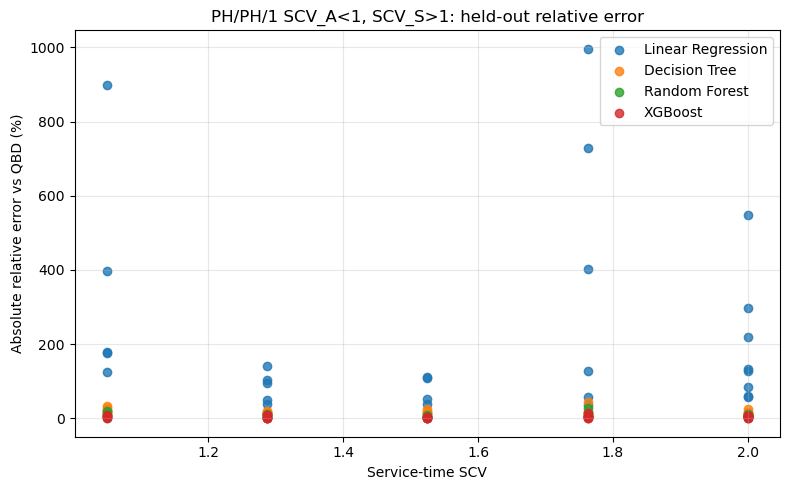

Linear Regression validation RMSE: 3.117916


,regime,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,p95_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,"SCV_A<1, SCV_S>1",300,1.0663,0.805,2.3171,2.9354,95.3333,2.8737


,Regime,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,"SCV_A<1, SCV_S>1",Linear Regression,simulation mean label,3.650847,5.690593,0.525239,213.562497,118.953931
1,"SCV_A<1, SCV_S>1",Linear Regression,QBD benchmark,3.595375,5.539612,0.534116,213.256975,117.580498
2,"SCV_A<1, SCV_S>1",Decision Tree,simulation mean label,0.634518,1.162377,0.980191,16.008589,15.177329
3,"SCV_A<1, SCV_S>1",Decision Tree,QBD benchmark,0.622688,1.040180,0.983574,16.278146,15.445634
4,"SCV_A<1, SCV_S>1",Random Forest,simulation mean label,0.412855,1.005363,0.985181,7.344001,6.575560
5,"SCV_A<1, SCV_S>1",Random Forest,QBD benchmark,0.383531,0.829861,0.989545,7.437462,6.850116
6,"SCV_A<1, SCV_S>1",XGBoost,simulation mean label,0.294123,0.725794,0.992277,4.278716,3.822757
7,"SCV_A<1, SCV_S>1",XGBoost,QBD benchmark,0.263694,0.583962,0.994823,4.002000,3.535728



===== Running SCV_A>1, SCV_S<1 =====
[1/300] gt1_lt1_000 rho=0.30, SCV_A=1.05, SCV_S=0.25
[25/300] gt1_lt1_024 rho=0.30, SCV_A=2.00, SCV_S=0.95
[50/300] gt1_lt1_049 rho=0.34, SCV_A=2.00, SCV_S=0.95
[75/300] gt1_lt1_074 rho=0.40, SCV_A=2.00, SCV_S=0.95
[100/300] gt1_lt1_099 rho=0.47, SCV_A=2.00, SCV_S=0.95
[125/300] gt1_lt1_124 rho=0.54, SCV_A=2.00, SCV_S=0.95
[150/300] gt1_lt1_149 rho=0.60, SCV_A=2.00, SCV_S=0.95
[175/300] gt1_lt1_174 rho=0.70, SCV_A=2.00, SCV_S=0.95
[200/300] gt1_lt1_199 rho=0.77, SCV_A=2.00, SCV_S=0.95
[225/300] gt1_lt1_224 rho=0.84, SCV_A=2.00, SCV_S=0.95
[250/300] gt1_lt1_249 rho=0.87, SCV_A=2.00, SCV_S=0.95
[275/300] gt1_lt1_274 rho=0.90, SCV_A=2.00, SCV_S=0.95
[300/300] gt1_lt1_299 rho=0.95, SCV_A=2.00, SCV_S=0.95
Full label generation completed in 0.25 minutes.


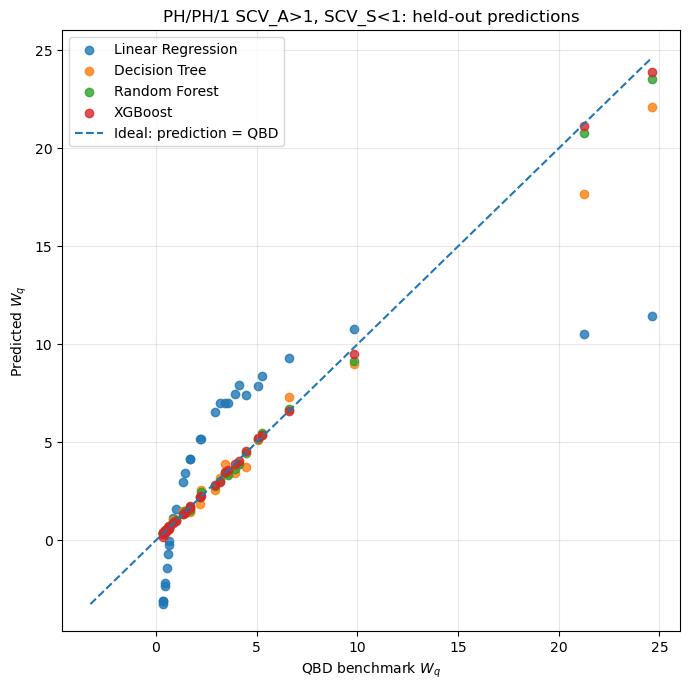

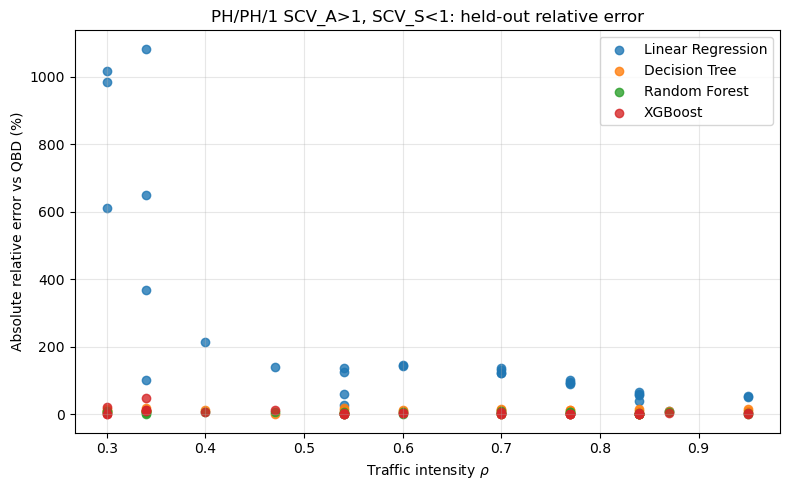

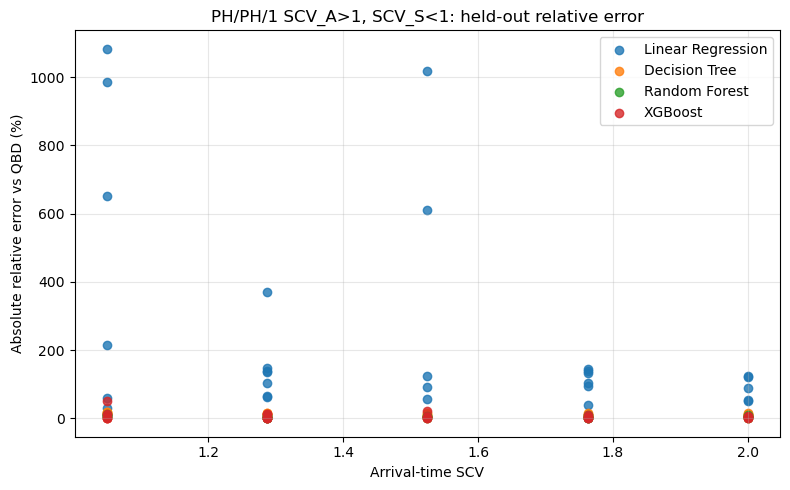

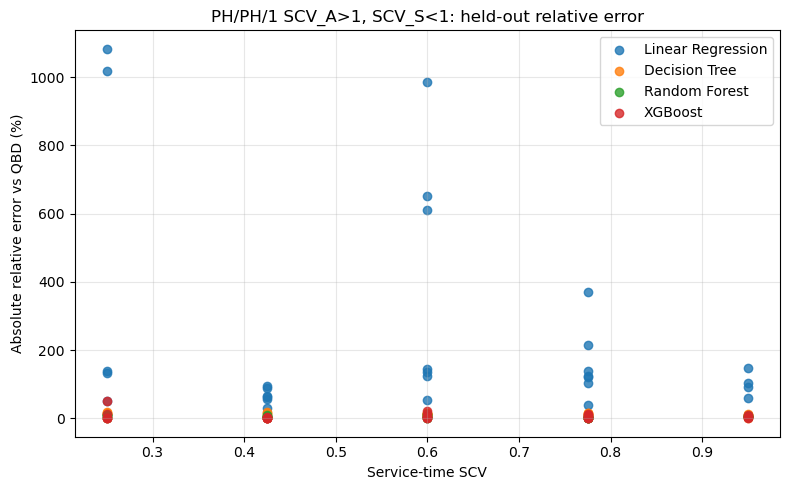

Linear Regression validation RMSE: 4.565811


,regime,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,p95_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,"SCV_A>1, SCV_S<1",300,0.9076,0.5927,2.0605,3.2425,95.3333,2.4422


,Regime,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,"SCV_A>1, SCV_S<1",Linear Regression,simulation mean label,3.172109,4.149180,0.458796,235.788918,125.059042
1,"SCV_A>1, SCV_S<1",Linear Regression,QBD benchmark,3.141487,4.072445,0.464855,234.907424,122.594114
2,"SCV_A>1, SCV_S<1",Decision Tree,simulation mean label,0.409555,0.904915,0.974257,10.172504,10.966131
3,"SCV_A>1, SCV_S<1",Decision Tree,QBD benchmark,0.408275,0.853057,0.976519,10.372459,11.118594
4,"SCV_A>1, SCV_S<1",Random Forest,simulation mean label,0.151832,0.379834,0.995465,4.882562,4.484510
5,"SCV_A>1, SCV_S<1",Random Forest,QBD benchmark,0.149417,0.271130,0.997628,5.011215,4.826280
6,"SCV_A>1, SCV_S<1",XGBoost,simulation mean label,0.117163,0.306917,0.997039,5.925399,2.604891
7,"SCV_A>1, SCV_S<1",XGBoost,QBD benchmark,0.096301,0.164307,0.999129,5.911613,2.744490



===== Running SCV_A>1, SCV_S>1 =====
[1/300] gt1_gt1_000 rho=0.30, SCV_A=1.05, SCV_S=1.05
[25/300] gt1_gt1_024 rho=0.30, SCV_A=2.00, SCV_S=2.00
[50/300] gt1_gt1_049 rho=0.34, SCV_A=2.00, SCV_S=2.00
[75/300] gt1_gt1_074 rho=0.40, SCV_A=2.00, SCV_S=2.00
[100/300] gt1_gt1_099 rho=0.47, SCV_A=2.00, SCV_S=2.00
[125/300] gt1_gt1_124 rho=0.54, SCV_A=2.00, SCV_S=2.00
[150/300] gt1_gt1_149 rho=0.60, SCV_A=2.00, SCV_S=2.00
[175/300] gt1_gt1_174 rho=0.70, SCV_A=2.00, SCV_S=2.00
[200/300] gt1_gt1_199 rho=0.77, SCV_A=2.00, SCV_S=2.00
[225/300] gt1_gt1_224 rho=0.84, SCV_A=2.00, SCV_S=2.00
[250/300] gt1_gt1_249 rho=0.87, SCV_A=2.00, SCV_S=2.00
[275/300] gt1_gt1_274 rho=0.90, SCV_A=2.00, SCV_S=2.00
[300/300] gt1_gt1_299 rho=0.95, SCV_A=2.00, SCV_S=2.00
Full label generation completed in 0.31 minutes.


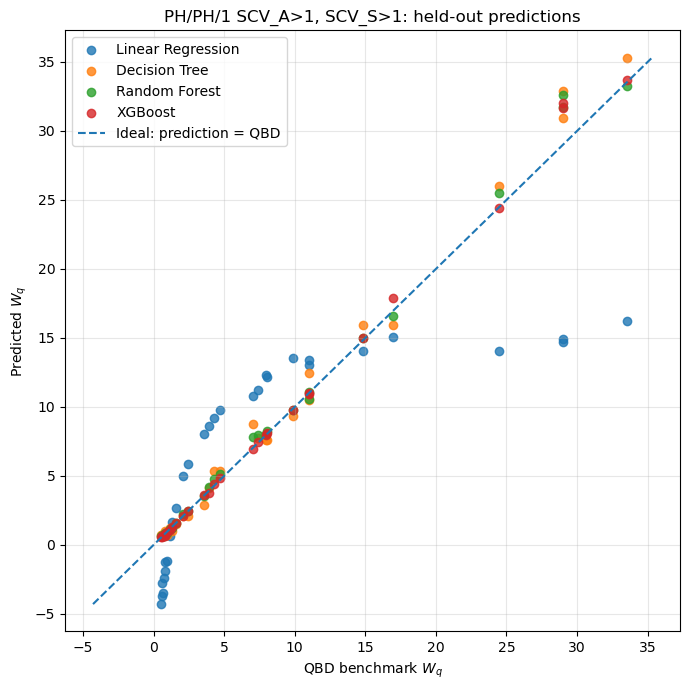

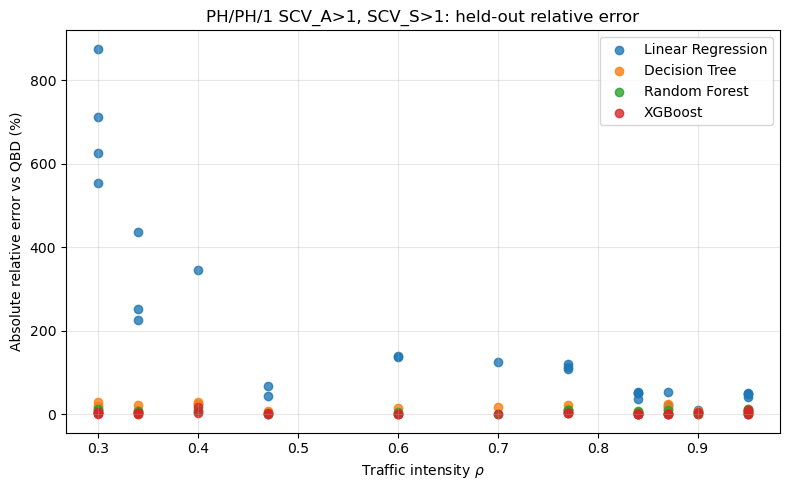

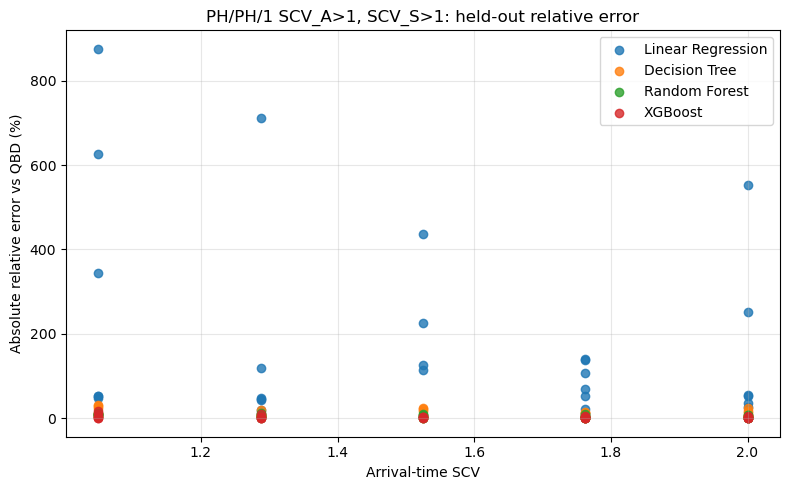

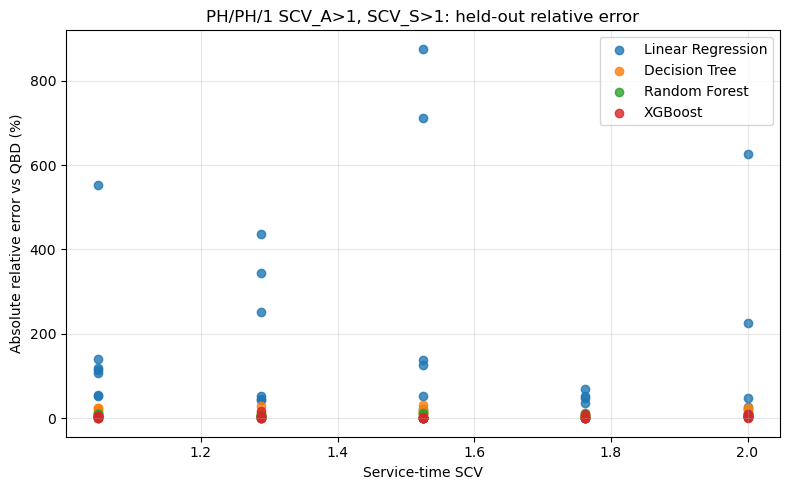

Linear Regression validation RMSE: 5.514177


,regime,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,p95_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,"SCV_A>1, SCV_S>1",300,1.2651,0.8361,2.9458,3.9127,94.3333,3.086


,Regime,Model,Reference,MAE,RMSE,R2,MAPE_pct,Median_APE_pct
0,"SCV_A>1, SCV_S>1",Linear Regression,simulation mean label,4.516389,6.081055,0.578536,179.836670,63.012625
1,"SCV_A>1, SCV_S>1",Linear Regression,QBD benchmark,4.563780,6.086989,0.578659,180.205357,61.215948
2,"SCV_A>1, SCV_S>1",Decision Tree,simulation mean label,0.712913,1.067332,0.987016,12.126845,9.692407
3,"SCV_A>1, SCV_S>1",Decision Tree,QBD benchmark,0.705566,1.086434,0.986577,12.086900,9.253396
4,"SCV_A>1, SCV_S>1",Random Forest,simulation mean label,0.432089,0.877092,0.991232,5.793391,5.584332
5,"SCV_A>1, SCV_S>1",Random Forest,QBD benchmark,0.419083,0.894094,0.990909,5.525808,5.390403
6,"SCV_A>1, SCV_S>1",XGBoost,simulation mean label,0.363746,0.764100,0.993346,3.485539,2.166917
7,"SCV_A>1, SCV_S>1",XGBoost,QBD benchmark,0.278657,0.769298,0.993270,2.906840,1.712092


In [28]:
joint_regime_results = {}

if RUN_REGIME_EXPERIMENTS:
    for regime_key, spec in JOINT_REGIME_SPECS.items():
        joint_regime_results[regime_key] = run_joint_regime_experiment(
            regime_key,
            spec,
            joint_regime_designs[regime_key],
        )
else:
    print("Regime-specific runs skipped. Set RUN_REGIME_EXPERIMENTS=True to run them.")


## 17. Cross-regime comparison

Before comparing ML errors, compare the quality of the simulation-generated labels against
QBD. Then compare the held-out ML performance across the four joint regimes.

Raw RMSE/MAE are retained for absolute error, but the regimes can have different `Wq` scales.
Therefore the cross-regime table also reports

\[
\mathrm{NRMSE}_{\mathrm{mean}}=
\frac{\mathrm{RMSE}}
{\operatorname{mean}(|W_q^{QBD}|)}\times100\%.
\]

MAPE, median APE, and NRMSE are used together with RMSE and R-squared rather than relying
on a single metric.


,regime,n_configurations,mean_relative_error_pct,median_relative_error_pct,p90_relative_error_pct,p95_relative_error_pct,ci95_coverage_pct,mean_relative_ci_halfwidth_pct
0,"SCV_A<1, SCV_S<1",300,0.8482,0.6611,1.8138,2.3608,93.0000,2.1514
1,"SCV_A<1, SCV_S>1",300,1.0663,0.8050,2.3171,2.9354,95.3333,2.8737
2,"SCV_A>1, SCV_S<1",300,0.9076,0.5927,2.0605,3.2425,95.3333,2.4422
3,"SCV_A>1, SCV_S>1",300,1.2651,0.8361,2.9458,3.9127,94.3333,3.0860


,Regime,Model,MAE,RMSE,NRMSE_mean_pct,R2,MAPE_pct,Median_APE_pct
1,"SCV_A<1, SCV_S<1",Decision Tree,0.467543,0.707681,26.747897,0.958608,47.726850,30.043450
5,"SCV_A<1, SCV_S>1",Decision Tree,0.622688,1.040180,18.934592,0.983574,16.278146,15.445634
9,"SCV_A>1, SCV_S<1",Decision Tree,0.408275,0.853057,22.263419,0.976519,10.372459,11.118594
13,"SCV_A>1, SCV_S>1",Decision Tree,0.705566,1.086434,13.532765,0.986577,12.086900,9.253396
0,"SCV_A<1, SCV_S<1",Linear Regression,1.704236,2.324118,87.843678,0.553560,490.170893,123.831553
4,"SCV_A<1, SCV_S>1",Linear Regression,3.595375,5.539612,100.838555,0.534116,213.256975,117.580498
8,"SCV_A>1, SCV_S<1",Linear Regression,3.141487,4.072445,106.284317,0.464855,234.907424,122.594114
12,"SCV_A>1, SCV_S>1",Linear Regression,4.563780,6.086989,75.820340,0.578659,180.205357,61.215948
2,"SCV_A<1, SCV_S<1",Random Forest,0.198446,0.371387,14.037150,0.988600,14.124072,10.209892
6,"SCV_A<1, SCV_S>1",Random Forest,0.383531,0.829861,15.106106,0.989545,7.437462,6.850116


RMSE                                    \
Regime            SCV_A<1, SCV_S<1 SCV_A<1, SCV_S>1 SCV_A>1, SCV_S<1   
Model                                                                  
Decision Tree             0.707681         1.040180         0.853057   
Linear Regression         2.324118         5.539612         4.072445   
Random Forest             0.371387         0.829861         0.271130   
XGBoost                   0.137984         0.583962         0.164307   

                                     NRMSE_mean_pct                   \
Regime            SCV_A>1, SCV_S>1 SCV_A<1, SCV_S<1 SCV_A<1, SCV_S>1   
Model                                                                  
Decision Tree             1.086434        26.747897        18.934592   
Linear Regression         6.086989        87.843678       100.838555   
Random Forest             0.894094        14.037150        15.106106   
XGBoost                   0.769298         5.215329        10.629967   

                                                                  R2  \
Regime            SCV_A>1, SCV_S<1 SCV_A>1, SCV_S>1 SCV_A<1, SCV_S<1   
Model                                                                  
Decision Tree            22.263419        13.532765         0.958608   
Linear Regression       106.284317        75.820340         0.553560   
Random Forest             7.076056        11.136950         0.988600   
XGBoost                   4.288140         9.582482         0.998426   

                                                                      \
Regime            SCV_A<1, SCV_S>1 SCV_A>1, SCV_S<1 SCV_A>1, SCV_S>1   
Model                                                                  
Decision Tree             0.983574         0.976519         0.986577   
Linear Regression         0.534116         0.464855         0.578659   
Random Forest             0.989545         0.997628         0.990909   
XGBoost                   0.994823         0.999129         0.993270   

                          MAPE_pct                                    \
Regime            SCV_A<1, SCV_S<1 SCV_A<1, SCV_S>1 SCV_A>1, SCV_S<1   
Model                                                                  
Decision Tree            47.726850        16.278146        10.372459   
Linear Regression       490.170893       213.256975       234.907424   
Random Forest            14.124072         7.437462         5.011215   
XGBoost                   7.711482         4.002000         5.911613   

                                     Median_APE_pct                   \
Regime            SCV_A>1, SCV_S>1 SCV_A<1, SCV_S<1 SCV_A<1, SCV_S>1   
Model                                                                  
Decision Tree            12.086900        30.043450        15.445634   
Linear Regression       180.205357       123.831553       117.580498   
Random Forest             5.525808        10.209892         6.850116   
XGBoost                   2.906840         3.143222         3.535728   

                                                     
Regime            SCV_A>1, SCV_S<1 SCV_A>1, SCV_S>1  
Model                                                
Decision Tree            11.118594         9.253396  
Linear Regression       122.594114        61.215948  
Random Forest             4.826280         5.390403  
XGBoost                   2.744490         1.712092

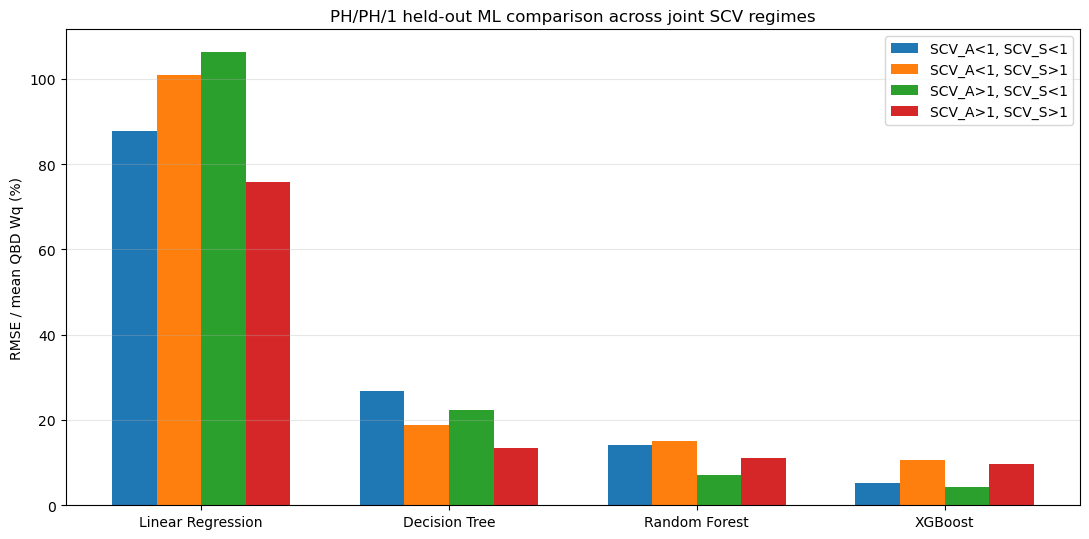

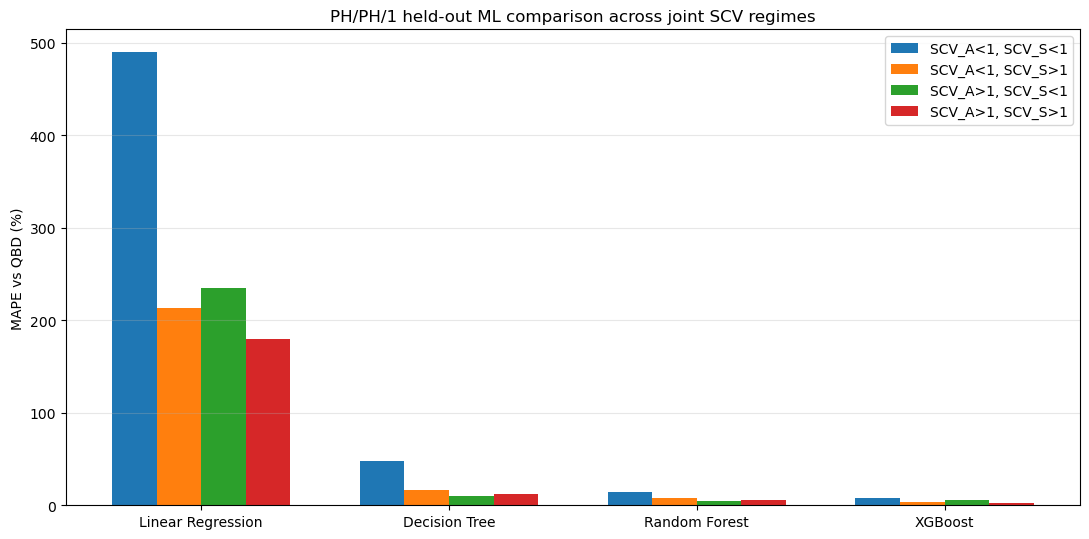

In [29]:
if RUN_REGIME_EXPERIMENTS:
    # 1) Simulation-label quality first.
    cross_regime_sim_quality = pd.concat(
        [r["simulation_summary"] for r in joint_regime_results.values()],
        ignore_index=True,
    )
    cross_regime_sim_quality.to_csv(
        OUTPUT_DIR / "phph1_joint_regime_simulation_quality_comparison.csv",
        index=False,
    )

    # 2) Held-out ML metrics against QBD with scale-aware normalisation.
    comparison_frames = []
    for key, result in joint_regime_results.items():
        qbd_metrics = result["metrics"][
            result["metrics"]["Reference"] == "QBD benchmark"
        ].copy()
        test_pred = result["predictions"]
        mean_abs_qbd = float(test_pred["Wq_qbd"].abs().mean())
        range_qbd = float(test_pred["Wq_qbd"].max() - test_pred["Wq_qbd"].min())
        qbd_metrics["mean_abs_Wq_qbd_test"] = mean_abs_qbd
        qbd_metrics["range_Wq_qbd_test"] = range_qbd
        qbd_metrics["NRMSE_mean_pct"] = 100.0 * qbd_metrics["RMSE"] / mean_abs_qbd
        qbd_metrics["NRMSE_range_pct"] = (
            100.0 * qbd_metrics["RMSE"] / range_qbd
            if range_qbd > 0 else np.nan
        )
        comparison_frames.append(qbd_metrics)

    cross_regime_ml_comparison = pd.concat(comparison_frames, ignore_index=True)
    cross_regime_ml_comparison.to_csv(
        OUTPUT_DIR / "phph1_joint_regime_ml_comparison.csv",
        index=False,
    )

    display(cross_regime_sim_quality.round(4))
    display(
        cross_regime_ml_comparison[
            [
                "Regime", "Model", "MAE", "RMSE", "NRMSE_mean_pct",
                "R2", "MAPE_pct", "Median_APE_pct",
            ]
        ].sort_values(["Model", "Regime"]).round(6)
    )

    # Wide table for direct reading.
    cross_regime_ml_wide = (
        cross_regime_ml_comparison[
            [
                "Regime", "Model", "RMSE", "NRMSE_mean_pct",
                "R2", "MAPE_pct", "Median_APE_pct",
            ]
        ]
        .pivot(index="Model", columns="Regime")
    )
    cross_regime_ml_wide.to_csv(
        OUTPUT_DIR / "phph1_joint_regime_ml_comparison_wide.csv"
    )
    display(cross_regime_ml_wide.round(6))

    # Scale-aware comparison plots.
    model_order = list(short_names.keys())
    regime_order = [spec["label"] for spec in JOINT_REGIME_SPECS.values()]
    x = np.arange(len(model_order))
    width = 0.18

    for metric, ylabel, filename in [
        (
            "NRMSE_mean_pct",
            "RMSE / mean QBD Wq (%)",
            "phph1_joint_regime_nrmse_mean_comparison.png",
        ),
        (
            "MAPE_pct",
            "MAPE vs QBD (%)",
            "phph1_joint_regime_mape_comparison.png",
        ),
    ]:
        fig, ax = plt.subplots(figsize=(11, 5.5))
        offsets = np.linspace(-1.5 * width, 1.5 * width, len(regime_order))
        for offset, regime_label in zip(offsets, regime_order):
            vals = [
                cross_regime_ml_comparison.loc[
                    (cross_regime_ml_comparison["Regime"] == regime_label)
                    & (cross_regime_ml_comparison["Model"] == model),
                    metric,
                ].iloc[0]
                for model in model_order
            ]
            ax.bar(x + offset, vals, width, label=regime_label)

        ax.set_xticks(x)
        ax.set_xticklabels(model_order)
        ax.set_ylabel(ylabel)
        ax.set_title("PH/PH/1 held-out ML comparison across joint SCV regimes")
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches="tight")
        plt.show()
else:
    print("Cross-regime comparison requires RUN_REGIME_EXPERIMENTS=True.")
